In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv(
    "Bitcoin Pulse  Hourly Dataset from Markets Trends and Fear.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (17516, 99)


In [ ]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

print(df["timestamp"].dtype)
print("Start:", df["timestamp"].min())
print("End:", df["timestamp"].max())

datetime64[ns]
Start: 2023-04-09 00:00:00
End: 2025-04-07 19:00:00


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
for i, column in enumerate(df.columns, start=1):
    print(i, column)

Rows: 17516
Columns: 99

Column names:
1 timestamp
2 BNB_USDT_1h_open
3 BNB_USDT_1h_high
4 BNB_USDT_1h_low
5 BNB_USDT_1h_close
6 BNB_USDT_1h_volume
7 BTC_USDT_1h_open
8 BTC_USDT_1h_high
9 BTC_USDT_1h_low
10 BTC_USDT_1h_close
11 BTC_USDT_1h_volume
12 DOGE_USDT_1h_open
13 DOGE_USDT_1h_high
14 DOGE_USDT_1h_low
15 DOGE_USDT_1h_close
16 DOGE_USDT_1h_volume
17 ETH_USDT_1h_open
18 ETH_USDT_1h_high
19 ETH_USDT_1h_low
20 ETH_USDT_1h_close
21 ETH_USDT_1h_volume
22 SOL_USDT_1h_open
23 SOL_USDT_1h_high
24 SOL_USDT_1h_low
25 SOL_USDT_1h_close
26 SOL_USDT_1h_volume
27 XRP_USDT_1h_open
28 XRP_USDT_1h_high
29 XRP_USDT_1h_low
30 XRP_USDT_1h_close
31 XRP_USDT_1h_volume
32 Close_ibovespa
33 High_ibovespa
34 Low_ibovespa
35 Open_ibovespa
36 Volume_ibovespa
37 Close_ipc_mexico
38 High_ipc_mexico
39 Low_ipc_mexico
40 Open_ipc_mexico
41 Volume_ipc_mexico
42 Close_dax
43 High_dax
44 Low_dax
45 Open_dax
46 Volume_dax
47 Close_nasdaq
48 High_nasdaq
49 Low_nasdaq
50 Open_nasdaq
51 Volume_nasdaq
52 Close_russell_

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17516 entries, 0 to 17515
Data columns (total 99 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   timestamp                 17516 non-null  datetime64[ns]
 1   BNB_USDT_1h_open          17516 non-null  float64       
 2   BNB_USDT_1h_high          17516 non-null  float64       
 3   BNB_USDT_1h_low           17516 non-null  float64       
 4   BNB_USDT_1h_close         17516 non-null  float64       
 5   BNB_USDT_1h_volume        17516 non-null  float64       
 6   BTC_USDT_1h_open          17516 non-null  float64       
 7   BTC_USDT_1h_high          17516 non-null  float64       
 8   BTC_USDT_1h_low           17516 non-null  float64       
 9   BTC_USDT_1h_close         17516 non-null  float64       
 10  BTC_USDT_1h_volume        17516 non-null  float64       
 11  DOGE_USDT_1h_open         17516 non-null  float64       
 12  DOGE_USDT_1h_high 

In [ ]:
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    )
})

missing_table = missing_table.sort_values(
    "Missing Values",
    ascending=False
)

missing_table.head(20)

,Missing Values,Missing Percentage
timestamp,0,0.0
BNB_USDT_1h_open,0,0.0
BNB_USDT_1h_high,0,0.0
BNB_USDT_1h_low,0,0.0
BNB_USDT_1h_close,0,0.0
BNB_USDT_1h_volume,0,0.0
BTC_USDT_1h_open,0,0.0
BTC_USDT_1h_high,0,0.0
BTC_USDT_1h_low,0,0.0
BTC_USDT_1h_close,0,0.0


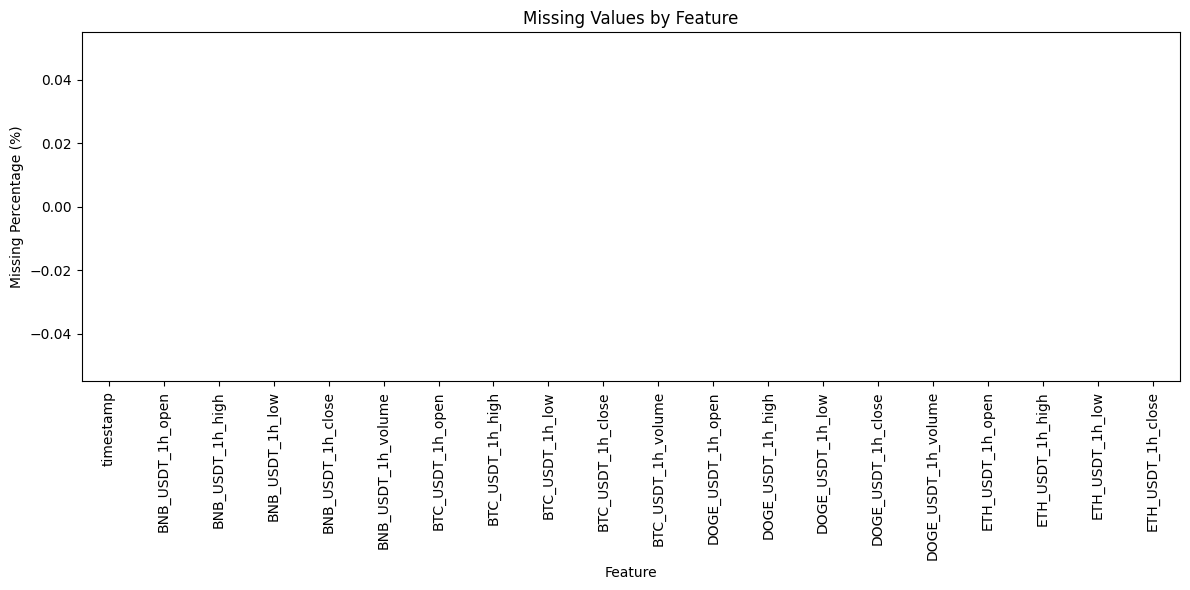

In [ ]:
plt.figure(figsize=(12, 6))

missing_table["Missing Percentage"].head(20).plot(
    kind="bar"
)

plt.title("Missing Values by Feature")
plt.xlabel("Feature")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
timestamp_duplicates = df["timestamp"].duplicated().sum()

print(
    "Duplicate timestamps:",
    timestamp_duplicates
)

Duplicate timestamps: 0


In [ ]:
df = df.sort_values("timestamp").reset_index(drop=True)

print(
    "Timestamps sorted:",
    df["timestamp"].is_monotonic_increasing
)

Timestamps sorted: True


In [ ]:
time_difference = (
    df["timestamp"]
    .diff()
    .value_counts()
)

print(time_difference.head(10))

timestamp
0 days 01:00:00    17515
Name: count, dtype: int64


In [ ]:
expected_interval = pd.Timedelta(hours=1)

gaps = df[
    df["timestamp"].diff() != expected_interval
]

print("Number of timestamp gaps:", len(gaps))

Number of timestamp gaps: 1


In [ ]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp,17516,2024-04-07 21:30:00,2023-04-09 00:00:00,2023-10-08 10:45:00,2024-04-07 21:30:00,2024-10-07 08:15:00,2025-04-07 19:00:00,NaN
BNB_USDT_1h_open,17516.0,449.579902,203.5328,250.0174,523.525,596.59185,783.95,174.385817
BNB_USDT_1h_high,17516.0,451.401201,204.6067,251.21045,526.005,598.38225,794.0,175.265286
BNB_USDT_1h_low,17516.0,447.61388,202.0268,248.9558,521.19,594.5225,775.85,173.421428
BNB_USDT_1h_close,17516.0,449.593638,203.5328,250.0174,523.605,596.59185,783.95,174.384341
...,...,...,...,...,...,...,...,...
trend_bitcoin,17516.0,39.481388,23.0,29.0,34.0,48.0,100.0,14.929269
trend_buy_crypto,17516.0,25.748116,12.0,17.0,20.0,26.0,100.0,15.799754
google_trends_bitcoin,17516.0,39.481388,23.0,29.0,34.0,48.0,100.0,14.929269
google_trends_buy_crypto,17516.0,25.748116,12.0,17.0,20.0,26.0,100.0,15.799754


In [ ]:
summary_stats = df.describe().T

summary_stats[
    [
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max"
    ]
]

,count,mean,std,min,25%,50%,75%,max
timestamp,17516,2024-04-07 21:30:00,NaN,2023-04-09 00:00:00,2023-10-08 10:45:00,2024-04-07 21:30:00,2024-10-07 08:15:00,2025-04-07 19:00:00
BNB_USDT_1h_open,17516.0,449.579902,174.385817,203.5328,250.0174,523.525,596.59185,783.95
BNB_USDT_1h_high,17516.0,451.401201,175.265286,204.6067,251.21045,526.005,598.38225,794.0
BNB_USDT_1h_low,17516.0,447.61388,173.421428,202.0268,248.9558,521.19,594.5225,775.85
BNB_USDT_1h_close,17516.0,449.593638,174.384341,203.5328,250.0174,523.605,596.59185,783.95
...,...,...,...,...,...,...,...,...
trend_bitcoin,17516.0,39.481388,14.929269,23.0,29.0,34.0,48.0,100.0
trend_buy_crypto,17516.0,25.748116,15.799754,12.0,17.0,20.0,26.0,100.0
google_trends_bitcoin,17516.0,39.481388,14.929269,23.0,29.0,34.0,48.0,100.0
google_trends_buy_crypto,17516.0,25.748116,15.799754,12.0,17.0,20.0,26.0,100.0


In [ ]:
crypto_features = [
    "BNB_USDT_1h_open",
    "BNB_USDT_1h_high",
    "BNB_USDT_1h_low",
    "BNB_USDT_1h_close",
    "BNB_USDT_1h_volume",

    "BTC_USDT_1h_open",
    "BTC_USDT_1h_high",
    "BTC_USDT_1h_low",
    "BTC_USDT_1h_close",
    "BTC_USDT_1h_volume",

    "DOGE_USDT_1h_open",
    "DOGE_USDT_1h_high",
    "DOGE_USDT_1h_low",
    "DOGE_USDT_1h_close",
    "DOGE_USDT_1h_volume",

    "ETH_USDT_1h_open",
    "ETH_USDT_1h_high",
    "ETH_USDT_1h_low",
    "ETH_USDT_1h_close",
    "ETH_USDT_1h_volume",

    "SOL_USDT_1h_open",
    "SOL_USDT_1h_high",
    "SOL_USDT_1h_low",
    "SOL_USDT_1h_close",
    "SOL_USDT_1h_volume",

    "XRP_USDT_1h_open",
    "XRP_USDT_1h_high",
    "XRP_USDT_1h_low",
    "XRP_USDT_1h_close",
    "XRP_USDT_1h_volume"
]

print("Crypto features:", len(crypto_features))

Crypto features: 30


In [ ]:
market_features = [
    "Close_ibovespa",
    "Close_ipc_mexico",
    "Close_dax",
    "Close_nasdaq",
    "Close_russell_2000",
    "Close_vix",
    "Close_cac_40",
    "Close_euro_stoxx_50",
    "Close_dow_jones",
    "Close_ftse_100",
    "Close_sptsx",
    "Close_sp500"
]

print("Global market features:", len(market_features))

Global market features: 12


In [ ]:
sentiment_features = [
    "btc_dominance",
    "altcoin_market_cap",
    "fear_greed_index",
    "trend_bitcoin",
    "trend_buy_crypto",
    "google_trends_bitcoin",
    "google_trends_buy_crypto",
    "open_interest"
]

print("Sentiment/market features:", len(sentiment_features))

Sentiment/market features: 8


In [ ]:
btc_df = df[
    [
        "timestamp",
        "BTC_USDT_1h_open",
        "BTC_USDT_1h_high",
        "BTC_USDT_1h_low",
        "BTC_USDT_1h_close",
        "BTC_USDT_1h_volume",
        "btc_dominance",
        "altcoin_market_cap",
        "fear_greed_index",
        "google_trends_bitcoin",
        "google_trends_buy_crypto",
        "open_interest",
        "Close_vix",
        "Close_nasdaq",
        "Close_sp500",
        "Close_dow_jones"
    ]
].copy()

btc_df.head()

,timestamp,BTC_USDT_1h_open,BTC_USDT_1h_high,BTC_USDT_1h_low,BTC_USDT_1h_close,BTC_USDT_1h_volume,btc_dominance,altcoin_market_cap,fear_greed_index,google_trends_bitcoin,google_trends_buy_crypto,open_interest,Close_vix,Close_nasdaq,Close_sp500,Close_dow_jones
0,2023-04-09 00:00:00,27943.39,28073.95,27930.31,28035.04,57.560631,19.43,6.817052e+11,61.0,38.0,17.0,8.142427e+09,19.389999,11944.575195,4077.27002,33439.53125
1,2023-04-09 01:00:00,28035.04,28080.00,28029.69,28075.72,21.191172,19.43,6.817052e+11,61.0,38.0,17.0,8.142427e+09,19.389999,11944.575195,4077.27002,33439.53125
2,2023-04-09 02:00:00,28075.72,28080.84,28027.47,28033.86,38.007310,19.43,6.817052e+11,61.0,38.0,17.0,8.142427e+09,19.389999,11944.575195,4077.27002,33439.53125
3,2023-04-09 03:00:00,28033.86,28047.09,28019.16,28025.87,9.248042,19.43,6.817052e+11,61.0,38.0,17.0,8.142427e+09,19.389999,11944.575195,4077.27002,33439.53125
4,2023-04-09 04:00:00,28025.87,28038.02,28016.28,28036.28,13.992617,19.43,6.817052e+11,61.0,38.0,17.0,8.142427e+09,19.389999,11944.575195,4077.27002,33439.53125


In [ ]:
btc_df[
    [
        "BTC_USDT_1h_open",
        "BTC_USDT_1h_high",
        "BTC_USDT_1h_low",
        "BTC_USDT_1h_close",
        "BTC_USDT_1h_volume"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
BTC_USDT_1h_open,17516.0,56629.480715,24184.088339,24924.36000,30405.330000,59415.210000,69356.970000,108322.4600
BTC_USDT_1h_high,17516.0,56834.612843,24293.718718,24974.05000,30471.902500,59643.950000,69519.157500,109900.0000
BTC_USDT_1h_low,17516.0,56418.535820,24072.415895,24394.74000,30334.442500,59193.790000,69147.797500,107794.0400
BTC_USDT_1h_close,17516.0,56632.388149,24183.700669,24924.36000,30407.497500,59420.930000,69358.085000,108322.4600
BTC_USDT_1h_volume,17516.0,606.837407,632.310603,7.71836,192.564846,425.702958,838.211382,15206.8683


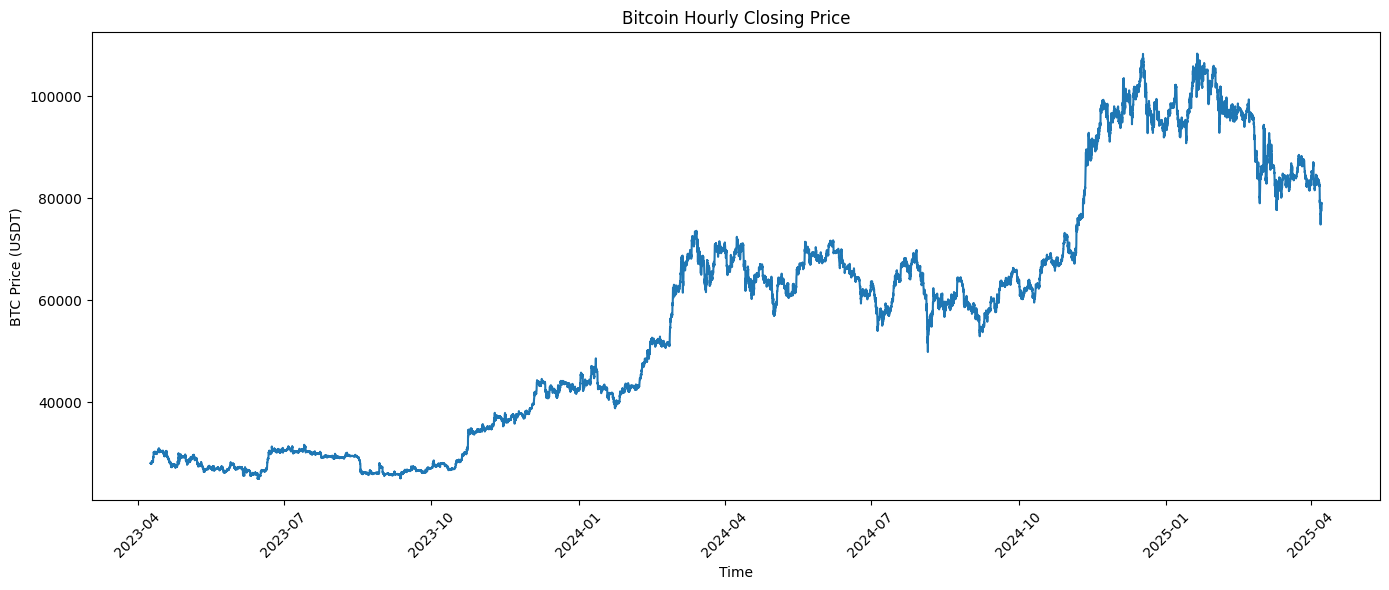

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    btc_df["timestamp"],
    btc_df["BTC_USDT_1h_close"]
)

plt.title("Bitcoin Hourly Closing Price")
plt.xlabel("Time")
plt.ylabel("BTC Price (USDT)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

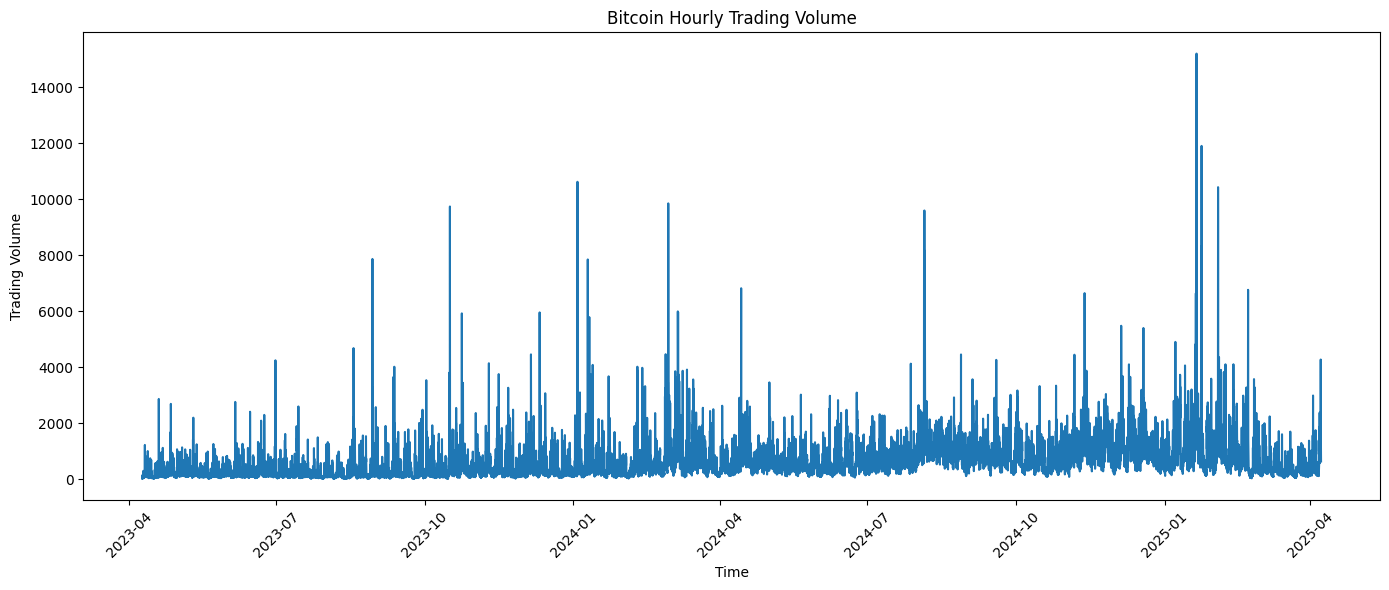

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    btc_df["timestamp"],
    btc_df["BTC_USDT_1h_volume"]
)

plt.title("Bitcoin Hourly Trading Volume")
plt.xlabel("Time")
plt.ylabel("Trading Volume")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

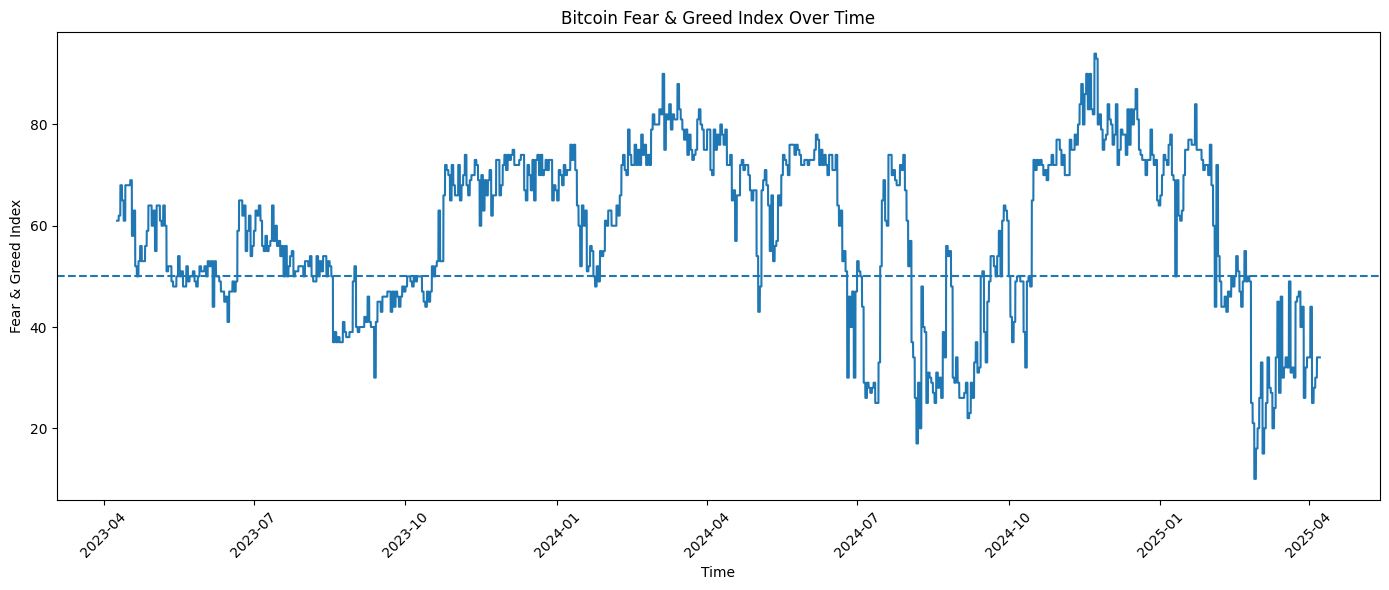

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    btc_df["timestamp"],
    btc_df["fear_greed_index"]
)

plt.title("Bitcoin Fear & Greed Index Over Time")
plt.xlabel("Time")
plt.ylabel("Fear & Greed Index")

plt.axhline(
    50,
    linestyle="--"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

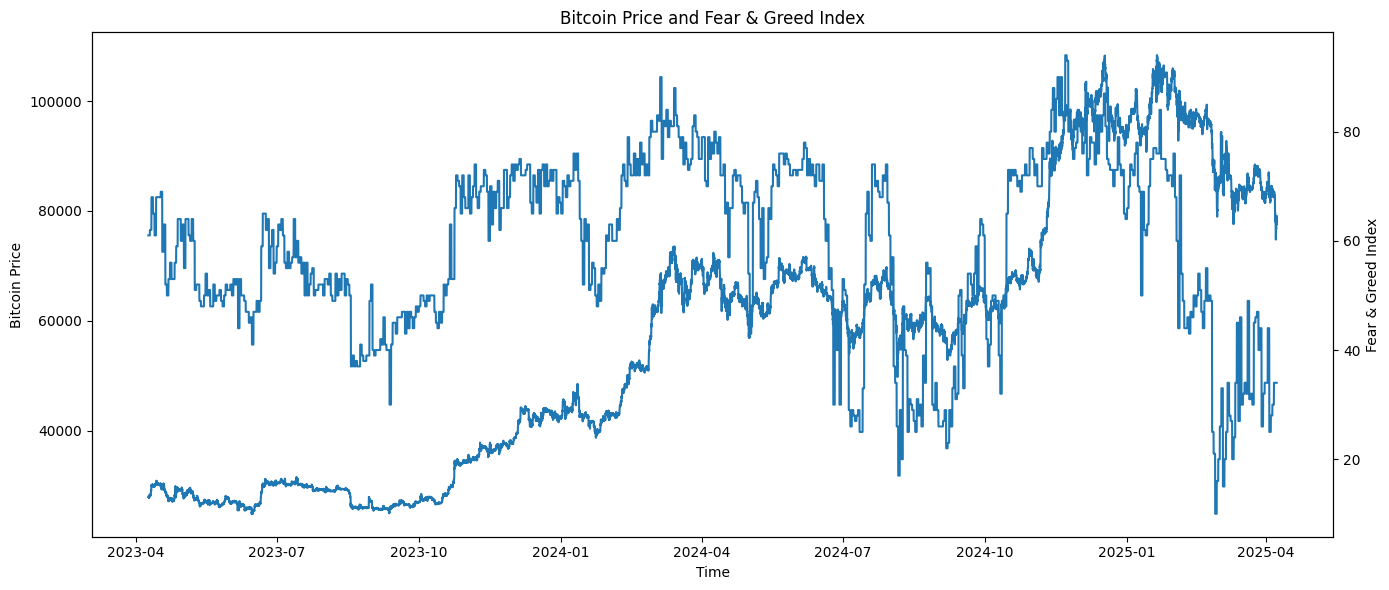

In [ ]:
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    btc_df["timestamp"],
    btc_df["BTC_USDT_1h_close"],
    label="Bitcoin Price"
)

ax1.set_xlabel("Time")
ax1.set_ylabel("Bitcoin Price")

ax2 = ax1.twinx()

ax2.plot(
    btc_df["timestamp"],
    btc_df["fear_greed_index"],
    label="Fear & Greed"
)

ax2.set_ylabel("Fear & Greed Index")

plt.title(
    "Bitcoin Price and Fear & Greed Index"
)

plt.tight_layout()
plt.show()

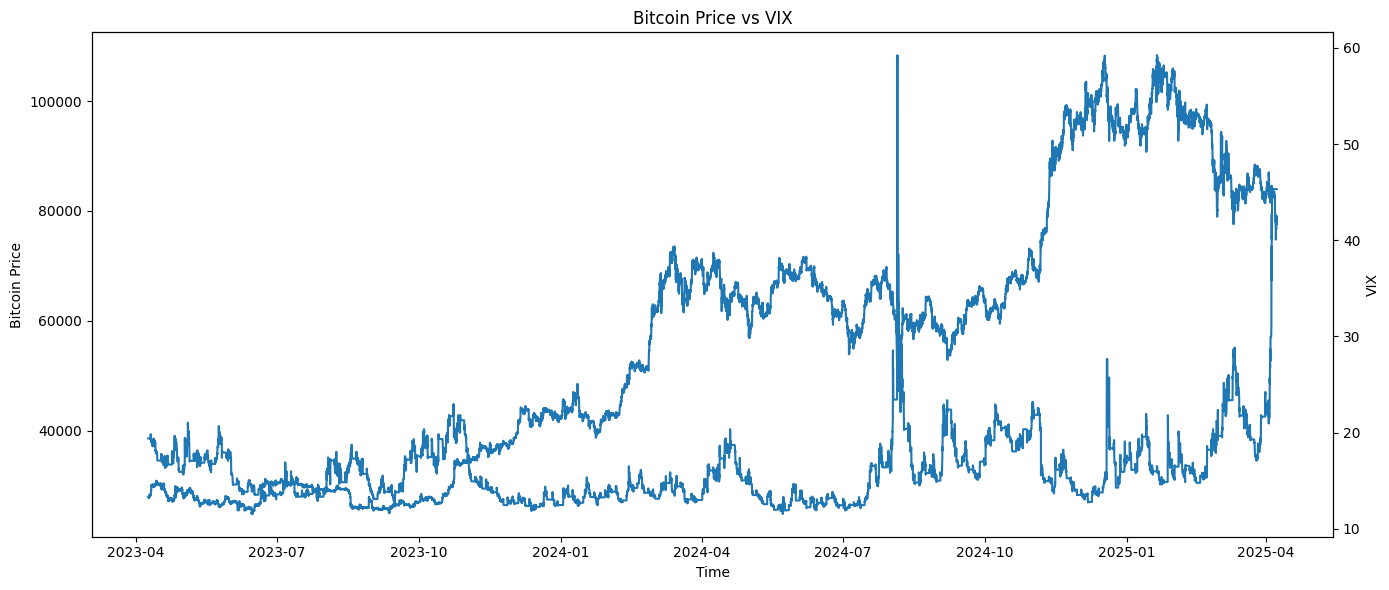

In [ ]:
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    btc_df["timestamp"],
    btc_df["BTC_USDT_1h_close"]
)

ax1.set_xlabel("Time")
ax1.set_ylabel("Bitcoin Price")

ax2 = ax1.twinx()

ax2.plot(
    btc_df["timestamp"],
    btc_df["Close_vix"]
)

ax2.set_ylabel("VIX")

plt.title(
    "Bitcoin Price vs VIX"
)

plt.tight_layout()
plt.show()

In [ ]:
# Create a separate dataframe for feature engineering
data = df.copy()

# Make sure data is sorted chronologically
data = data.sort_values("timestamp").reset_index(drop=True)

print("Shape:", data.shape)

Shape: (17516, 99)


In [ ]:
data["btc_return"] = (
    data["BTC_USDT_1h_close"]
    .pct_change() * 100
)

data[[
    "timestamp",
    "BTC_USDT_1h_close",
    "btc_return"
]].head(10)

,timestamp,BTC_USDT_1h_close,btc_return
0,2023-04-09 00:00:00,28035.04,NaN
1,2023-04-09 01:00:00,28075.72,0.145104
2,2023-04-09 02:00:00,28033.86,-0.149097
3,2023-04-09 03:00:00,28025.87,-0.028501
4,2023-04-09 04:00:00,28036.28,0.037144
5,2023-04-09 05:00:00,27997.74,-0.137465
6,2023-04-09 06:00:00,27882.11,-0.412998
7,2023-04-09 07:00:00,27909.00,0.096442
8,2023-04-09 08:00:00,27880.83,-0.100935
9,2023-04-09 09:00:00,27897.42,0.059503


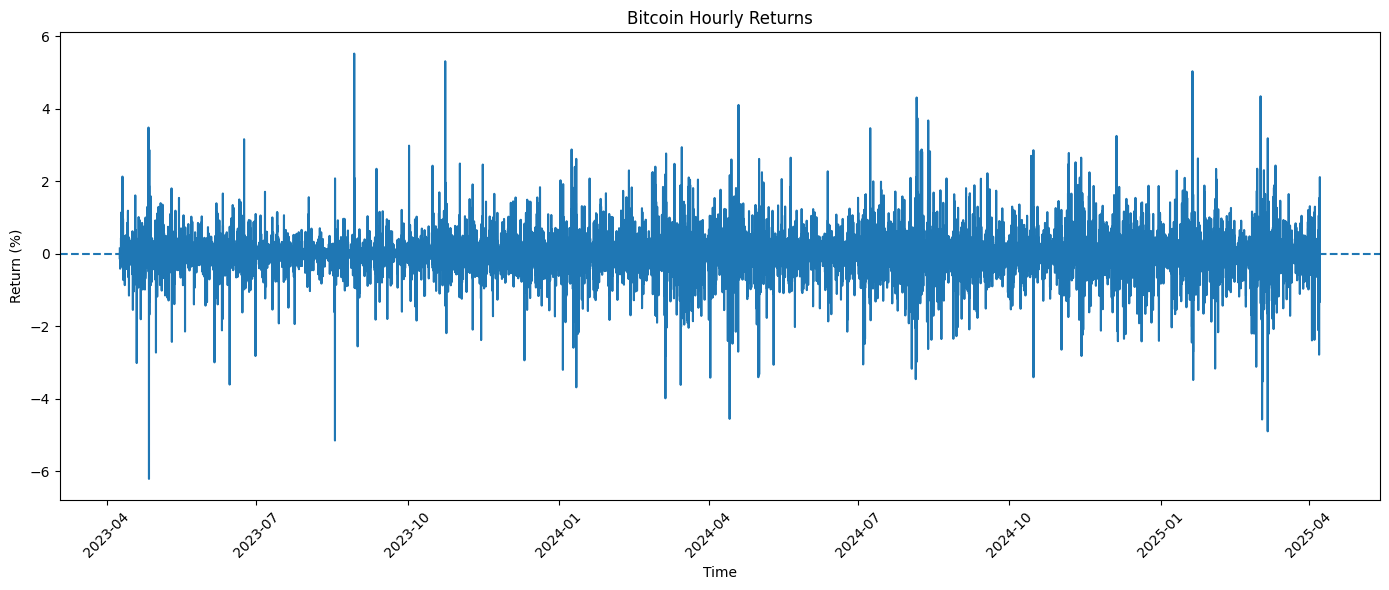

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    data["timestamp"],
    data["btc_return"]
)

plt.axhline(0, linestyle="--")

plt.title("Bitcoin Hourly Returns")
plt.xlabel("Time")
plt.ylabel("Return (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
data["btc_price_range"] = (
    data["BTC_USDT_1h_high"]
    - data["BTC_USDT_1h_low"]
)

In [ ]:
data["btc_range_pct"] = (
    data["btc_price_range"]
    / data["BTC_USDT_1h_close"]
) * 100

In [ ]:
data[[
    "BTC_USDT_1h_high",
    "BTC_USDT_1h_low",
    "BTC_USDT_1h_close",
    "btc_price_range",
    "btc_range_pct"
]].head()

,BTC_USDT_1h_high,BTC_USDT_1h_low,BTC_USDT_1h_close,btc_price_range,btc_range_pct
0,28073.95,27930.31,28035.04,143.64,0.512359
1,28080.00,28029.69,28075.72,50.31,0.179194
2,28080.84,28027.47,28033.86,53.37,0.190377
3,28047.09,28019.16,28025.87,27.93,0.099658
4,28038.02,28016.28,28036.28,21.74,0.077542


In [ ]:
data["btc_volume_change_pct"] = (
    data["BTC_USDT_1h_volume"]
    .pct_change() * 100
)

In [ ]:
data["btc_volatility_6h"] = (
    data["btc_return"]
    .rolling(window=6)
    .std()
)

In [ ]:
data["btc_volatility_24h"] = (
    data["btc_return"]
    .rolling(window=24)
    .std()
)

In [ ]:
data["btc_ma_6h"] = (
    data["BTC_USDT_1h_close"]
    .rolling(window=6)
    .mean()
)

In [ ]:
data["btc_ma_24h"] = (
    data["BTC_USDT_1h_close"]
    .rolling(window=24)
    .mean()
)

In [ ]:
data["btc_ma_72h"] = (
    data["BTC_USDT_1h_close"]
    .rolling(window=72)
    .mean()
)

In [ ]:
data["btc_ma_24h_diff_pct"] = (
    (
        data["BTC_USDT_1h_close"]
        - data["btc_ma_24h"]
    )
    / data["btc_ma_24h"]
) * 100

In [ ]:
data["btc_price_lag_1h"] = (
    data["BTC_USDT_1h_close"].shift(1)
)

In [ ]:
data["btc_price_lag_3h"] = (
    data["BTC_USDT_1h_close"].shift(3)
)

In [ ]:
data["btc_price_lag_6h"] = (
    data["BTC_USDT_1h_close"].shift(6)
)

In [ ]:
data["btc_return_lag_1h"] = (
    data["btc_return"].shift(1)
)

In [ ]:
data["btc_return_lag_3h"] = (
    data["btc_return"].shift(3)
)

In [ ]:
data["eth_return"] = (
    data["ETH_USDT_1h_close"]
    .pct_change() * 100
)

In [ ]:
data["bnb_return"] = (
    data["BNB_USDT_1h_close"]
    .pct_change() * 100
)

In [ ]:
data["sol_return"] = (
    data["SOL_USDT_1h_close"]
    .pct_change() * 100
)

In [ ]:
data["xrp_return"] = (
    data["XRP_USDT_1h_close"]
    .pct_change() * 100
)

In [ ]:
data["doge_return"] = (
    data["DOGE_USDT_1h_close"]
    .pct_change() * 100
)

In [ ]:
data["nasdaq_return"] = (
    data["Close_nasdaq"]
    .pct_change() * 100
)

In [ ]:
data["sp500_return"] = (
    data["Close_sp500"]
    .pct_change() * 100
)

In [ ]:
data["dow_return"] = (
    data["Close_dow_jones"]
    .pct_change() * 100
)

In [ ]:
data["russell_return"] = (
    data["Close_russell_2000"]
    .pct_change() * 100
)

In [ ]:
data["vix_change_pct"] = (
    data["Close_vix"]
    .pct_change() * 100
)

In [ ]:
data["btc_dominance_change"] = (
    data["btc_dominance"]
    .pct_change() * 100
)

In [ ]:
data["altcoin_market_cap_change"] = (
    data["altcoin_market_cap"]
    .pct_change() * 100
)

In [ ]:
data["fear_greed_change"] = (
    data["fear_greed_index"]
    .diff()
)

In [ ]:
data["bitcoin_trend_change"] = (
    data["google_trends_bitcoin"]
    .diff()
)

data["buy_crypto_trend_change"] = (
    data["google_trends_buy_crypto"]
    .diff()
)

In [ ]:
data["open_interest_change_pct"] = (
    data["open_interest"]
    .pct_change() * 100
)

In [ ]:
data["hour"] = data["timestamp"].dt.hour
data["day_of_week"] = data["timestamp"].dt.dayofweek
data["day"] = data["timestamp"].dt.day
data["month"] = data["timestamp"].dt.month

In [ ]:
data["is_weekend"] = (
    data["day_of_week"] >= 5
).astype(int)

In [ ]:
data["next_hour_return"] = (
    data["btc_return"].shift(-1)
)

In [ ]:
data["btc_direction"] = (
    data["next_hour_return"] > 0
).astype(int)

In [ ]:
data[[
    "timestamp",
    "BTC_USDT_1h_close",
    "btc_return",
    "next_hour_return",
    "btc_direction"
]].head(15)

,timestamp,BTC_USDT_1h_close,btc_return,next_hour_return,btc_direction
0,2023-04-09 00:00:00,28035.04,NaN,0.145104,1
1,2023-04-09 01:00:00,28075.72,0.145104,-0.149097,0
2,2023-04-09 02:00:00,28033.86,-0.149097,-0.028501,0
3,2023-04-09 03:00:00,28025.87,-0.028501,0.037144,1
4,2023-04-09 04:00:00,28036.28,0.037144,-0.137465,0
5,2023-04-09 05:00:00,27997.74,-0.137465,-0.412998,0
6,2023-04-09 06:00:00,27882.11,-0.412998,0.096442,1
7,2023-04-09 07:00:00,27909.00,0.096442,-0.100935,0
8,2023-04-09 08:00:00,27880.83,-0.100935,0.059503,1
9,2023-04-09 09:00:00,27897.42,0.059503,-0.019106,0


In [ ]:
engineered_features = [
    "btc_return",
    "btc_price_range",
    "btc_range_pct",
    "btc_volume_change_pct",
    "btc_volatility_6h",
    "btc_volatility_24h",
    "btc_ma_6h",
    "btc_ma_24h",
    "btc_ma_72h",
    "btc_ma_24h_diff_pct",
    "btc_price_lag_1h",
    "btc_price_lag_3h",
    "btc_price_lag_6h",
    "btc_return_lag_1h",
    "btc_return_lag_3h",
    "eth_return",
    "bnb_return",
    "sol_return",
    "xrp_return",
    "doge_return",
    "nasdaq_return",
    "sp500_return",
    "dow_return",
    "russell_return",
    "vix_change_pct",
    "btc_dominance_change",
    "altcoin_market_cap_change",
    "fear_greed_change",
    "bitcoin_trend_change",
    "buy_crypto_trend_change",
    "open_interest_change_pct",
    "hour",
    "day_of_week",
    "is_weekend"
]

print("Number of engineered features:", len(engineered_features))

Number of engineered features: 34


In [ ]:
data_ml = data.dropna(
    subset=engineered_features + [
        "next_hour_return",
        "btc_direction"
    ]
).copy()

print("Original rows:", len(data))
print("Rows after feature engineering:", len(data_ml))

Original rows: 17516
Rows after feature engineering: 17444


In [ ]:
data_ml[
    engineered_features + [
        "next_hour_return",
        "btc_direction"
    ]
].head()

,btc_return,btc_price_range,btc_range_pct,btc_volume_change_pct,btc_volatility_6h,btc_volatility_24h,btc_ma_6h,btc_ma_24h,btc_ma_72h,btc_ma_24h_diff_pct,...,altcoin_market_cap_change,fear_greed_change,bitcoin_trend_change,buy_crypto_trend_change,open_interest_change_pct,hour,day_of_week,is_weekend,next_hour_return,btc_direction
71,-0.200318,109.82,0.363628,-27.609976,0.225027,0.414790,30195.830000,30119.627083,28919.881944,0.270929,...,0.0,0.0,0.0,0.0,0.000000,23,1,0,0.088308,1
72,0.088308,151.63,0.501623,87.086420,0.226530,0.369224,30195.475000,30132.205833,28950.338333,0.317581,...,0.0,-3.0,0.0,0.0,-1.504051,0,2,0,-0.178544,0
73,-0.178544,171.68,0.568968,-16.907396,0.178981,0.323800,30203.840000,30131.389167,28979.480139,0.141184,...,0.0,0.0,0.0,0.0,0.000000,1,2,0,-0.867106,0
74,-0.867106,343.94,1.149828,270.920255,0.393376,0.361949,30161.056667,30124.340000,29005.569444,-0.703916,...,0.0,0.0,0.0,0.0,0.000000,2,2,0,0.032996,1
75,0.032996,128.77,0.430350,-64.995156,0.390022,0.361237,30116.560000,30116.465000,29031.906806,-0.645179,...,0.0,0.0,0.0,0.0,0.000000,3,2,0,0.192566,1


In [ ]:
data_ml[engineered_features].describe().T

,count,mean,std,min,25%,50%,75%,max
btc_return,17444.0,0.006844,0.518547,-6.213776,-0.195050,0.006549,0.215432,5.522605
btc_price_range,17444.0,417.074656,433.688834,2.180000,146.437500,296.210000,530.857500,8245.200000
btc_range_pct,17444.0,0.689241,0.595152,0.007414,0.338551,0.531496,0.847030,12.714243
btc_volume_change_pct,17444.0,18.867576,107.096121,-90.219722,-27.985843,-2.919710,34.223764,3626.461175
btc_volatility_6h,17444.0,0.416725,0.311855,0.016994,0.208662,0.335344,0.527202,3.249537
btc_volatility_24h,17444.0,0.455132,0.248062,0.044303,0.291161,0.413866,0.558137,2.119952
btc_ma_6h,17444.0,56737.035575,24166.278449,24964.558333,30470.202917,59499.195833,69385.623750,107929.963333
btc_ma_24h,17444.0,56712.666797,24162.281788,25061.414583,30497.063542,59529.079167,69361.089479,106792.000000
btc_ma_72h,17444.0,56641.048353,24150.608665,25542.466389,30452.237431,59437.177708,69216.696563,105474.709861
btc_ma_24h_diff_pct,17444.0,0.066862,1.387621,-10.934097,-0.545815,0.036938,0.659822,9.817936


In [ ]:
direction_counts = data_ml["btc_direction"].value_counts()

print(direction_counts)

print("\nPercentage:")
print(
    data_ml["btc_direction"]
    .value_counts(normalize=True) * 100
)

btc_direction
1    8886
0    8558
Name: count, dtype: int64

Percentage:
btc_direction
1    50.940151
0    49.059849
Name: proportion, dtype: float64


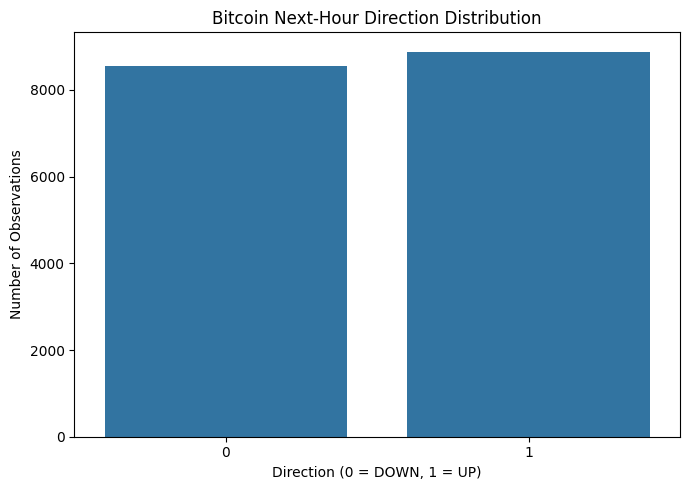

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data_ml,
    x="btc_direction"
)

plt.title("Bitcoin Next-Hour Direction Distribution")
plt.xlabel("Direction (0 = DOWN, 1 = UP)")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

In [ ]:
data_ml.to_csv(
    "bitcoin_feature_engineered.csv",
    index=False
)

print("Feature-engineered dataset saved successfully!")

Feature-engineered dataset saved successfully!


EDA:

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Basic statistics of Bitcoin returns
print("Bitcoin Return Statistics:")
print(data_ml["btc_return"].describe())

# Skewness and kurtosis
print("\nSkewness:", data_ml["btc_return"].skew())
print("Kurtosis:", data_ml["btc_return"].kurtosis())

Bitcoin Return Statistics:
count    17444.000000
mean         0.006844
std          0.518547
min         -6.213776
25%         -0.195050
50%          0.006549
75%          0.215432
max          5.522605
Name: btc_return, dtype: float64

Skewness: -0.19868172561493133
Kurtosis: 12.440999438037474


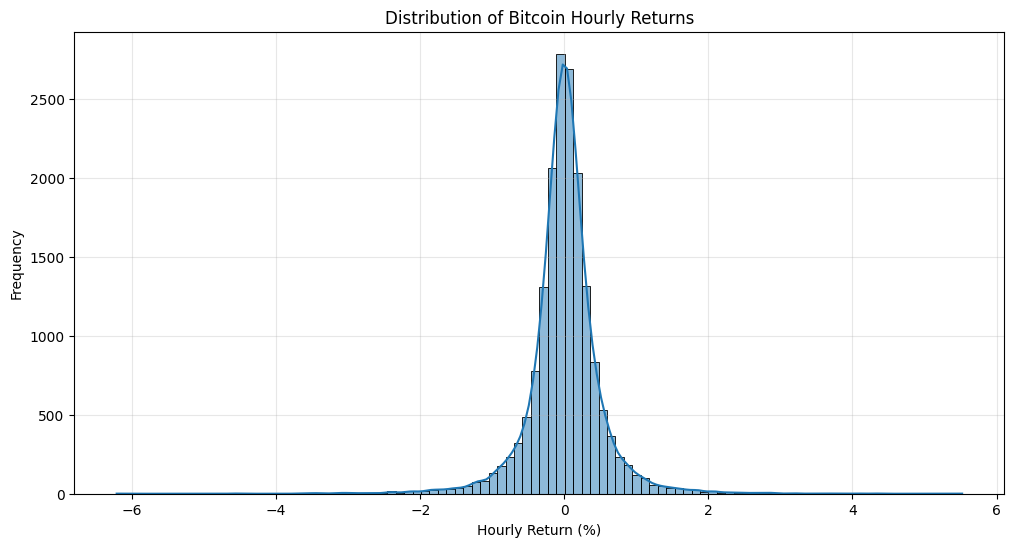

In [ ]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data_ml["btc_return"],
    bins=100,
    kde=True
)

plt.title("Distribution of Bitcoin Hourly Returns")
plt.xlabel("Hourly Return (%)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.show()

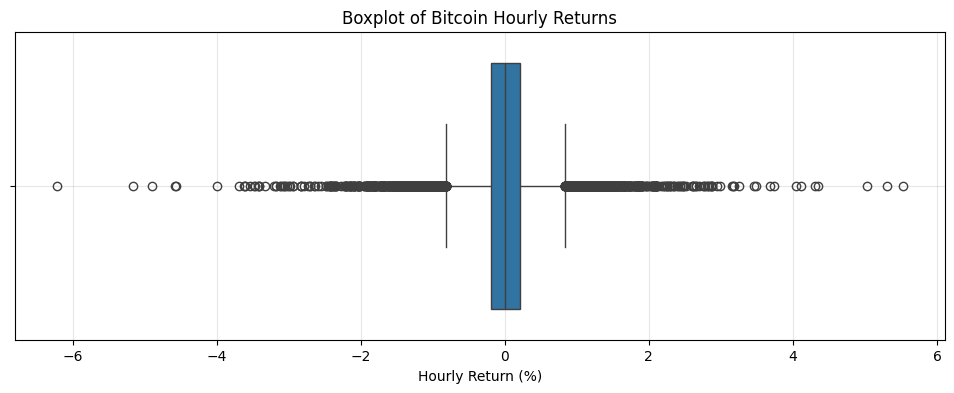

In [ ]:
plt.figure(figsize=(12, 4))

sns.boxplot(x=data_ml["btc_return"])

plt.title("Boxplot of Bitcoin Hourly Returns")
plt.xlabel("Hourly Return (%)")
plt.grid(alpha=0.3)

plt.show()

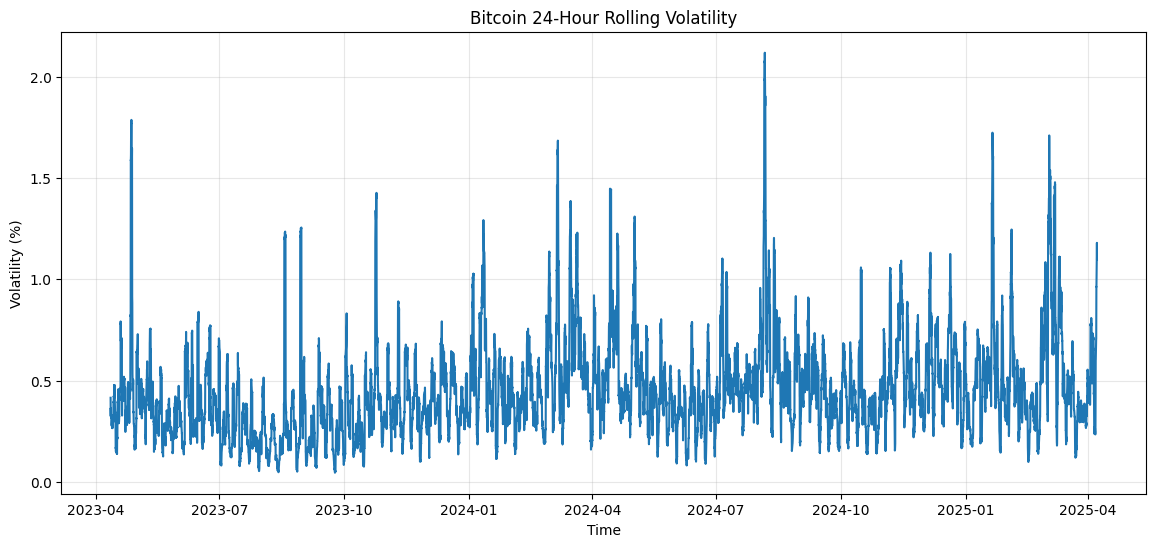

In [ ]:
# Bitcoin volatility over time

plt.figure(figsize=(14, 6))

plt.plot(
    data_ml["timestamp"],
    data_ml["btc_volatility_24h"]
)

plt.title("Bitcoin 24-Hour Rolling Volatility")
plt.xlabel("Time")
plt.ylabel("Volatility (%)")
plt.grid(alpha=0.3)

plt.show()

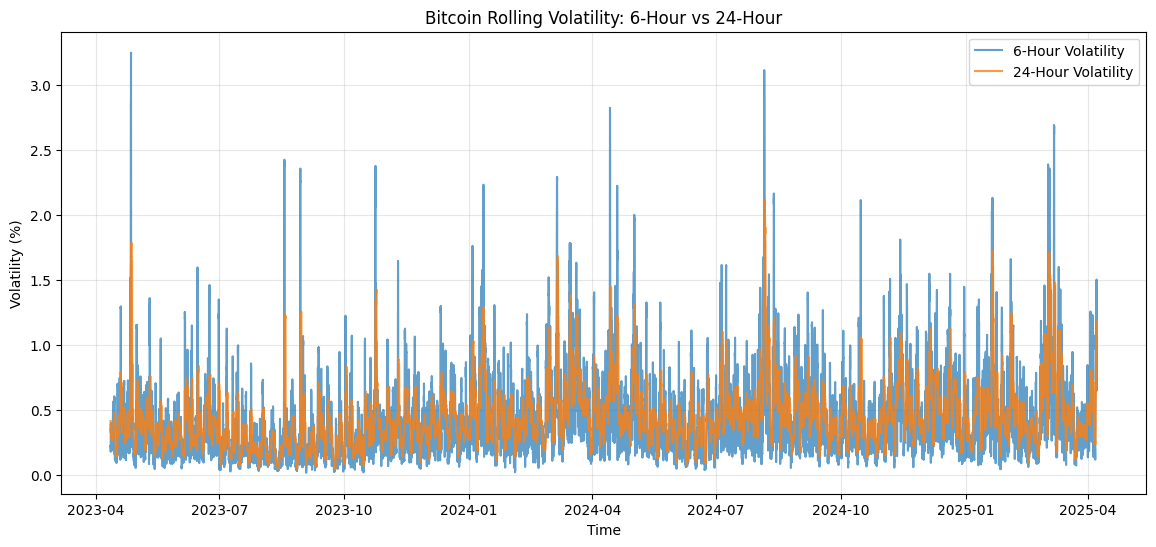

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    data_ml["timestamp"],
    data_ml["btc_volatility_6h"],
    label="6-Hour Volatility",
    alpha=0.7
)

plt.plot(
    data_ml["timestamp"],
    data_ml["btc_volatility_24h"],
    label="24-Hour Volatility",
    alpha=0.8
)

plt.title("Bitcoin Rolling Volatility: 6-Hour vs 24-Hour")
plt.xlabel("Time")
plt.ylabel("Volatility (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
print("6-Hour Volatility Statistics:")
print(data_ml["btc_volatility_6h"].describe())

print("\n24-Hour Volatility Statistics:")
print(data_ml["btc_volatility_24h"].describe())

6-Hour Volatility Statistics:
count    17444.000000
mean         0.416725
std          0.311855
min          0.016994
25%          0.208662
50%          0.335344
75%          0.527202
max          3.249537
Name: btc_volatility_6h, dtype: float64

24-Hour Volatility Statistics:
count    17444.000000
mean         0.455132
std          0.248062
min          0.044303
25%          0.291161
50%          0.413866
75%          0.558137
max          2.119952
Name: btc_volatility_24h, dtype: float64


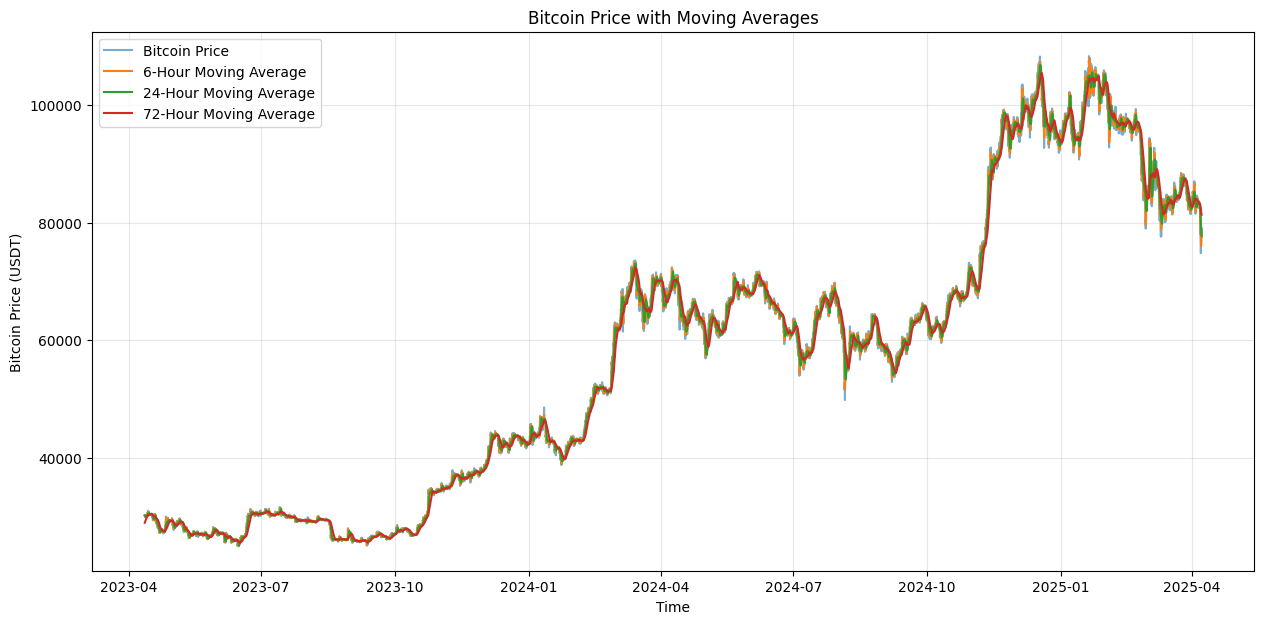

In [ ]:
plt.figure(figsize=(15, 7))

plt.plot(
    data_ml["timestamp"],
    data_ml["BTC_USDT_1h_close"],
    label="Bitcoin Price",
    alpha=0.6
)

plt.plot(
    data_ml["timestamp"],
    data_ml["btc_ma_6h"],
    label="6-Hour Moving Average"
)

plt.plot(
    data_ml["timestamp"],
    data_ml["btc_ma_24h"],
    label="24-Hour Moving Average"
)

plt.plot(
    data_ml["timestamp"],
    data_ml["btc_ma_72h"],
    label="72-Hour Moving Average"
)

plt.title("Bitcoin Price with Moving Averages")
plt.xlabel("Time")
plt.ylabel("Bitcoin Price (USDT)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

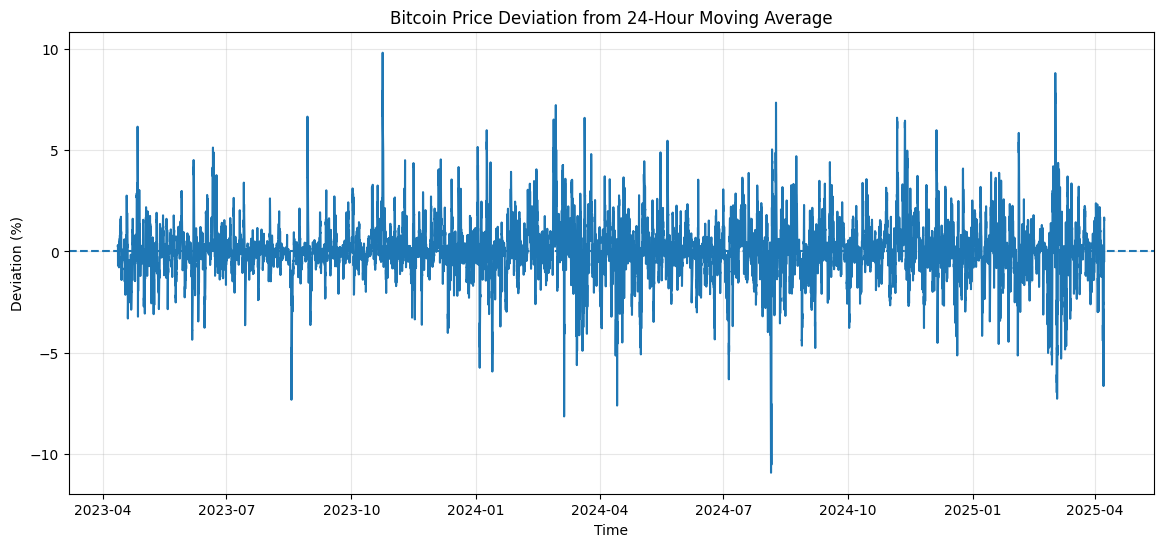

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    data_ml["timestamp"],
    data_ml["btc_ma_24h_diff_pct"]
)

plt.axhline(0, linestyle="--")

plt.title("Bitcoin Price Deviation from 24-Hour Moving Average")
plt.xlabel("Time")
plt.ylabel("Deviation (%)")
plt.grid(alpha=0.3)

plt.show()

In [ ]:
print("BTC 24-Hour Moving Average Deviation:")
print(data_ml["btc_ma_24h_diff_pct"].describe())

BTC 24-Hour Moving Average Deviation:
count    17444.000000
mean         0.066862
std          1.387621
min        -10.934097
25%         -0.545815
50%          0.036938
75%          0.659822
max          9.817936
Name: btc_ma_24h_diff_pct, dtype: float64


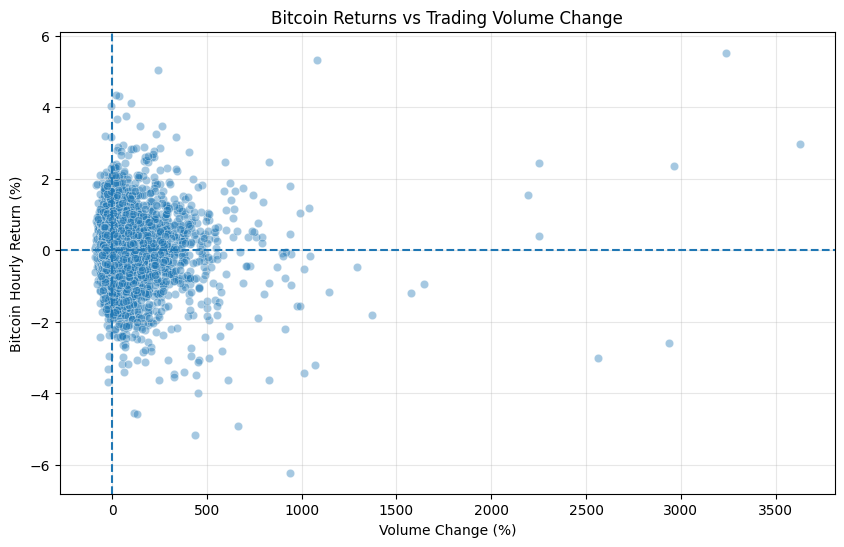

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data_ml,
    x="btc_volume_change_pct",
    y="btc_return",
    alpha=0.4
)

plt.axhline(0, linestyle="--")
plt.axvline(0, linestyle="--")

plt.title("Bitcoin Returns vs Trading Volume Change")
plt.xlabel("Volume Change (%)")
plt.ylabel("Bitcoin Hourly Return (%)")
plt.grid(alpha=0.3)

plt.show()

In [ ]:
correlation = data_ml[
    ["btc_volume_change_pct", "btc_return"]
].corr()

print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
                       btc_volume_change_pct  btc_return
btc_volume_change_pct                1.00000    -0.02316
btc_return                          -0.02316     1.00000


In [ ]:
corr_value = data_ml["btc_volume_change_pct"].corr(
    data_ml["btc_return"]
)

print(f"Correlation between BTC volume change and return: {corr_value:.4f}")

Correlation between BTC volume change and return: -0.0232


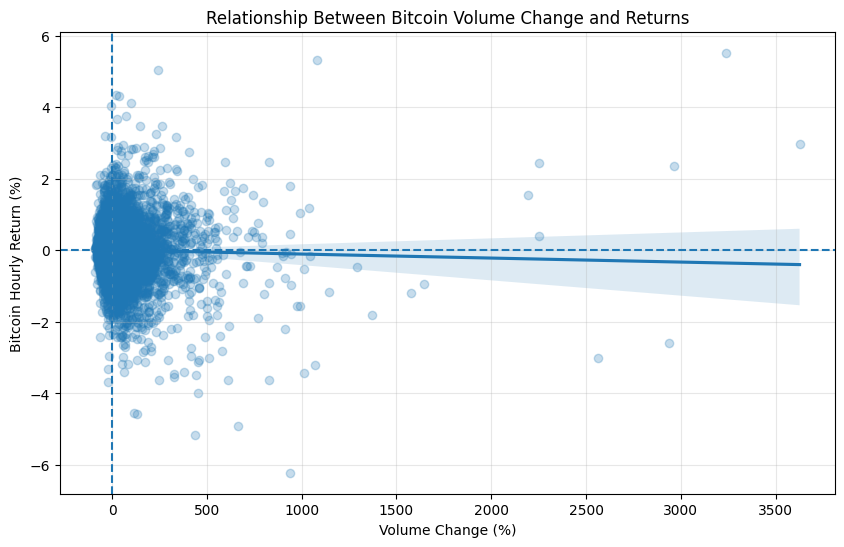

In [ ]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=data_ml,
    x="btc_volume_change_pct",
    y="btc_return",
    scatter_kws={"alpha": 0.25},
    line_kws={}
)

plt.axhline(0, linestyle="--")
plt.axvline(0, linestyle="--")

plt.title("Relationship Between Bitcoin Volume Change and Returns")
plt.xlabel("Volume Change (%)")
plt.ylabel("Bitcoin Hourly Return (%)")
plt.grid(alpha=0.3)

plt.show()

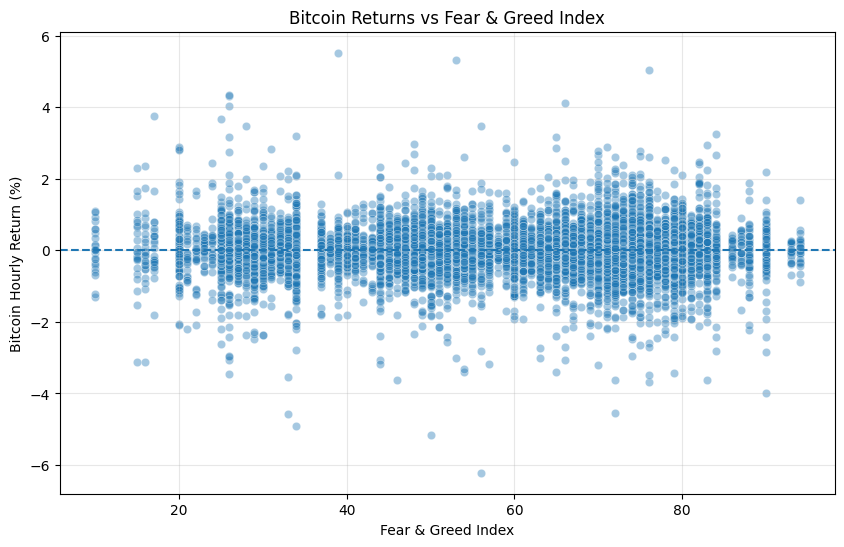

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data_ml,
    x="fear_greed_index",
    y="btc_return",
    alpha=0.4
)

plt.axhline(0, linestyle="--")

plt.title("Bitcoin Returns vs Fear & Greed Index")
plt.xlabel("Fear & Greed Index")
plt.ylabel("Bitcoin Hourly Return (%)")
plt.grid(alpha=0.3)

plt.show()

In [ ]:
corr_fg = data_ml[
    ["fear_greed_index", "btc_return"]
].corr()

print("Correlation Matrix:")
print(corr_fg)

fg_corr_value = data_ml["fear_greed_index"].corr(
    data_ml["btc_return"]
)

print(
    f"\nCorrelation between Fear & Greed and BTC return: "
    f"{fg_corr_value:.4f}"
)

Correlation Matrix:
                  fear_greed_index  btc_return
fear_greed_index          1.000000   -0.003512
btc_return               -0.003512    1.000000

Correlation between Fear & Greed and BTC return: -0.0035


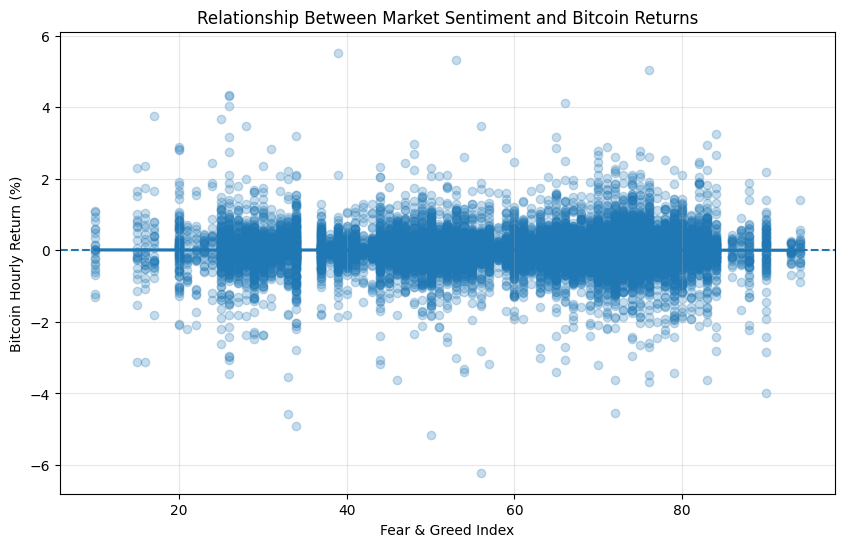

In [ ]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=data_ml,
    x="fear_greed_index",
    y="btc_return",
    scatter_kws={"alpha": 0.25}
)

plt.axhline(0, linestyle="--")

plt.title("Relationship Between Market Sentiment and Bitcoin Returns")
plt.xlabel("Fear & Greed Index")
plt.ylabel("Bitcoin Hourly Return (%)")
plt.grid(alpha=0.3)

plt.show()

In [ ]:
def sentiment_category(value):
    if value <= 25:
        return "Extreme Fear"
    elif value <= 45:
        return "Fear"
    elif value <= 55:
        return "Neutral"
    elif value <= 75:
        return "Greed"
    else:
        return "Extreme Greed"


data_ml["sentiment_category"] = data_ml["fear_greed_index"].apply(
    sentiment_category
)

print(
    data_ml.groupby("sentiment_category")["btc_return"]
    .agg(["count", "mean", "std", "min", "max"])
    .reindex([
        "Extreme Fear",
        "Fear",
        "Neutral",
        "Greed",
        "Extreme Greed"
    ])
)

                    count      mean       std       min       max
sentiment_category                                               
Extreme Fear          456  0.042900  0.795727 -3.120145  3.741638
Fear                 2875  0.007087  0.578563 -4.900810  5.522605
Neutral              4368 -0.000871  0.407418 -5.154396  5.311446
Greed                7489  0.012417  0.490345 -6.213776  4.105803
Extreme Greed        2256 -0.004315  0.636475 -3.989681  5.034889


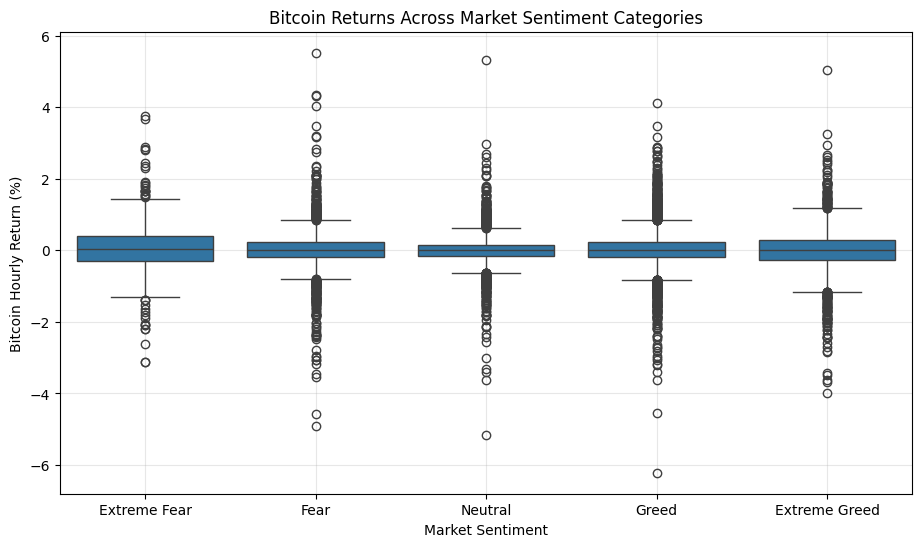

In [ ]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=data_ml,
    x="sentiment_category",
    y="btc_return",
    order=[
        "Extreme Fear",
        "Fear",
        "Neutral",
        "Greed",
        "Extreme Greed"
    ]
)

plt.title("Bitcoin Returns Across Market Sentiment Categories")
plt.xlabel("Market Sentiment")
plt.ylabel("Bitcoin Hourly Return (%)")
plt.grid(alpha=0.3)

plt.show()

In [ ]:
[col for col in data_ml.columns if "vix" in col.lower()]

['Close_vix',
 'High_vix',
 'Low_vix',
 'Open_vix',
 'Volume_vix',
 'vix_change_pct']

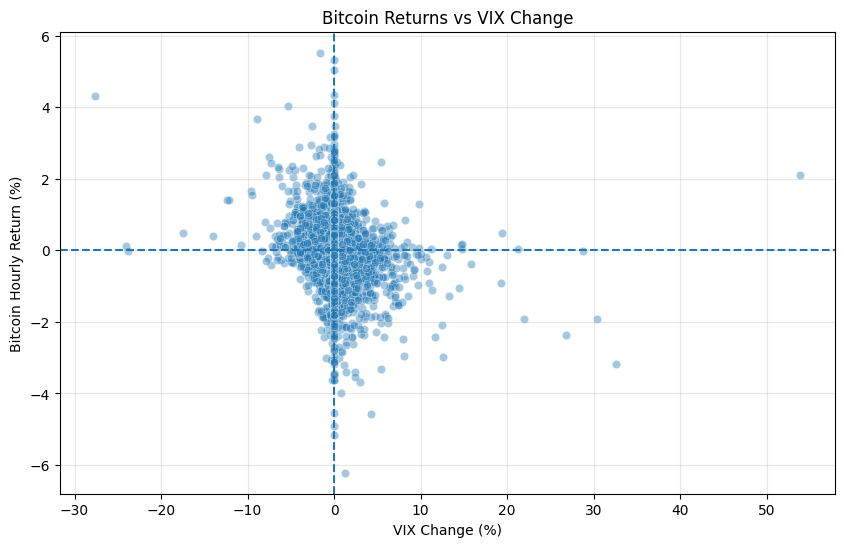

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data_ml,
    x="vix_change_pct",
    y="btc_return",
    alpha=0.4
)

plt.axhline(0, linestyle="--")
plt.axvline(0, linestyle="--")

plt.title("Bitcoin Returns vs VIX Change")
plt.xlabel("VIX Change (%)")
plt.ylabel("Bitcoin Hourly Return (%)")
plt.grid(alpha=0.3)

plt.show()

In [ ]:
vix_corr = data_ml[
    ["vix_change_pct", "btc_return"]
].corr()

print("Correlation Matrix:")
print(vix_corr)

vix_corr_value = data_ml["vix_change_pct"].corr(
    data_ml["btc_return"]
)

print(
    f"\nCorrelation between VIX change and BTC return: "
    f"{vix_corr_value:.4f}"
)

Correlation Matrix:
                vix_change_pct  btc_return
vix_change_pct        1.000000   -0.202247
btc_return           -0.202247    1.000000

Correlation between VIX change and BTC return: -0.2022


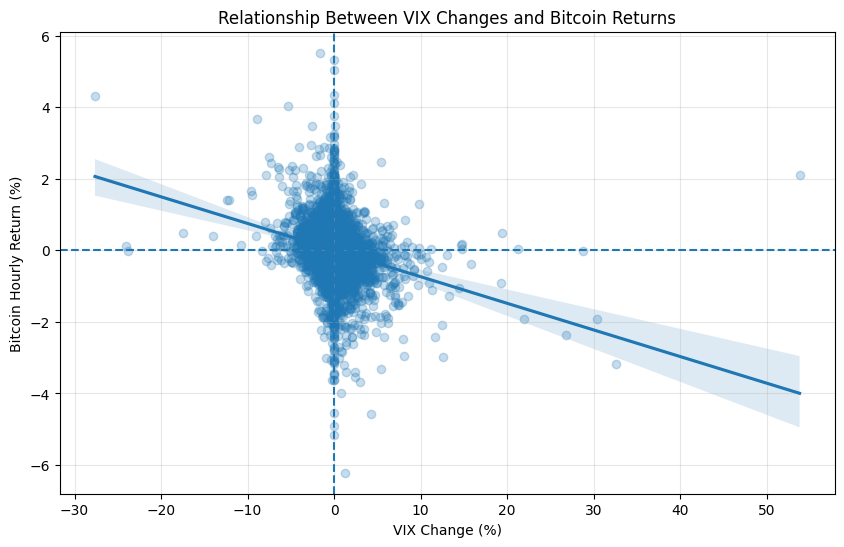

In [ ]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=data_ml,
    x="vix_change_pct",
    y="btc_return",
    scatter_kws={"alpha": 0.25}
)

plt.axhline(0, linestyle="--")
plt.axvline(0, linestyle="--")

plt.title("Relationship Between VIX Changes and Bitcoin Returns")
plt.xlabel("VIX Change (%)")
plt.ylabel("Bitcoin Hourly Return (%)")
plt.grid(alpha=0.3)

plt.show()

In [ ]:
data_ml["vix_direction"] = np.where(
    data_ml["vix_change_pct"] > 0,
    "VIX Increasing",
    "VIX Decreasing"
)

vix_comparison = (
    data_ml.groupby("vix_direction")["btc_return"]
    .agg(["count", "mean", "std", "min", "max"])
)

print(vix_comparison)

                count      mean       std       min       max
vix_direction                                                
VIX Decreasing  14286  0.035818  0.486454 -5.154396  5.522605
VIX Increasing   3158 -0.124228  0.627643 -6.213776  3.463967


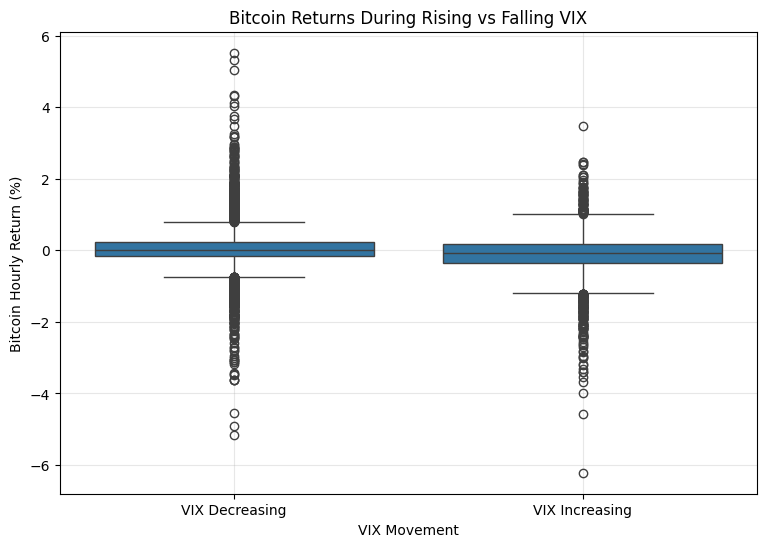

In [ ]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=data_ml,
    x="vix_direction",
    y="btc_return"
)

plt.title("Bitcoin Returns During Rising vs Falling VIX")
plt.xlabel("VIX Movement")
plt.ylabel("Bitcoin Hourly Return (%)")
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# Traditional market returns vs Bitcoin returns

market_corr = data_ml[
    [
        "btc_return",
        "nasdaq_return",
        "sp500_return",
        "dow_return",
        "russell_return"
    ]
].corr()

print("Traditional Market vs Bitcoin Correlation Matrix:")
print(market_corr.round(4))

Traditional Market vs Bitcoin Correlation Matrix:
                btc_return  nasdaq_return  sp500_return  dow_return  \
btc_return          1.0000         0.0984        0.0900      0.0694   
nasdaq_return       0.0984         1.0000        0.9506      0.7201   
sp500_return        0.0900         0.9506        1.0000      0.8749   
dow_return          0.0694         0.7201        0.8749      1.0000   
russell_return      0.0881         0.7011        0.7817      0.7851   

                russell_return  
btc_return              0.0881  
nasdaq_return           0.7011  
sp500_return            0.7817  
dow_return              0.7851  
russell_return          1.0000  


In [ ]:
# Display only correlations with Bitcoin

btc_market_corr = market_corr["btc_return"].sort_values(ascending=False)

print("\nCorrelation of Traditional Markets with Bitcoin Returns:")
print(btc_market_corr.round(4))


Correlation of Traditional Markets with Bitcoin Returns:
btc_return        1.0000
nasdaq_return     0.0984
sp500_return      0.0900
russell_return    0.0881
dow_return        0.0694
Name: btc_return, dtype: float64


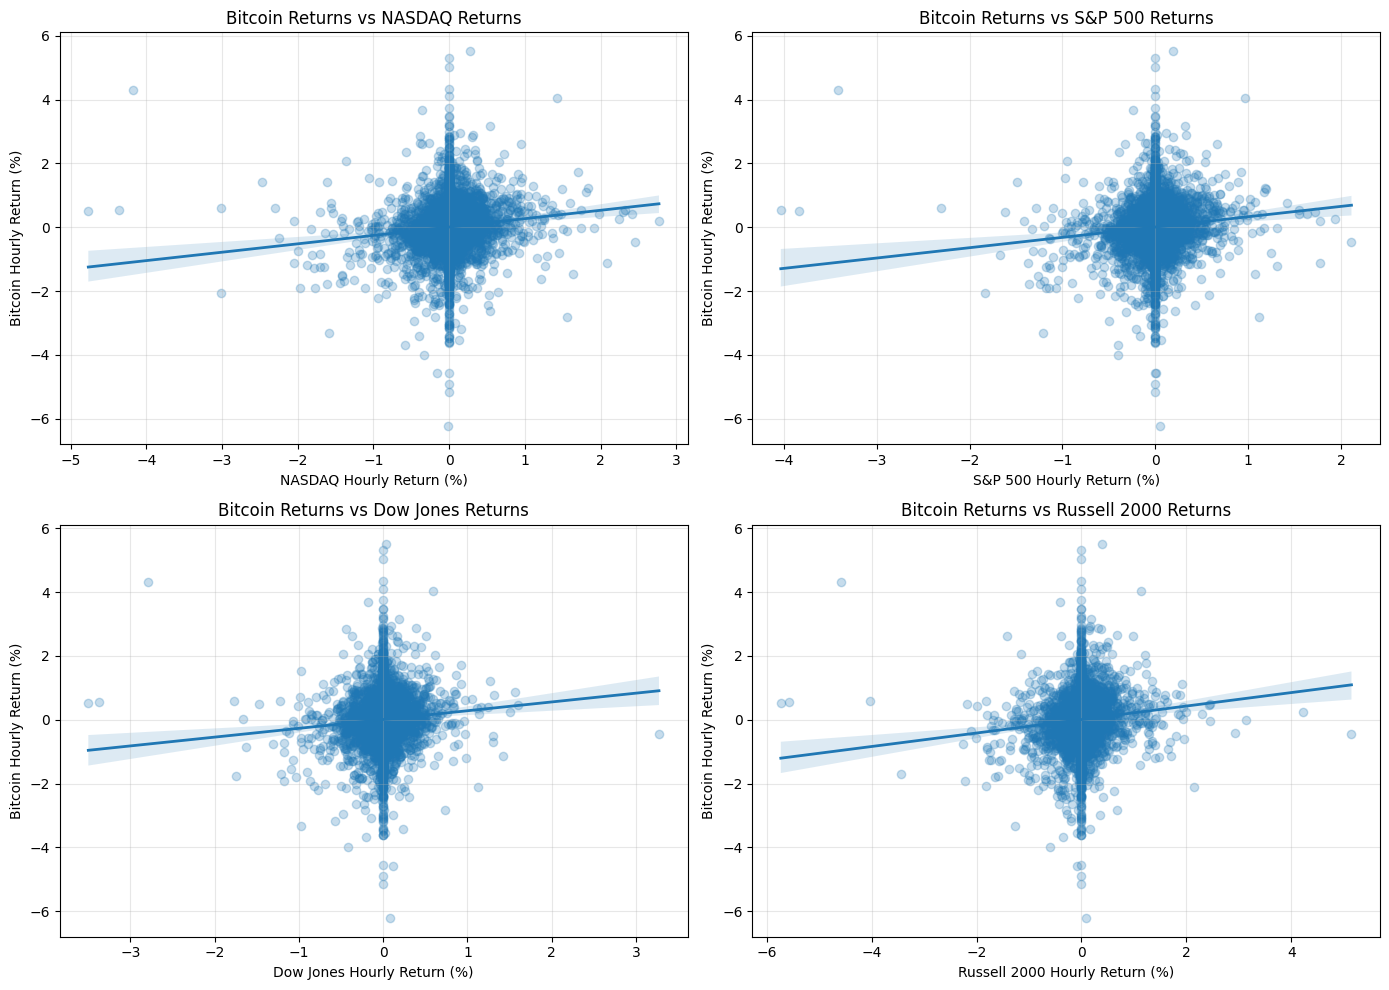

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

markets = [
    ("nasdaq_return", "NASDAQ"),
    ("sp500_return", "S&P 500"),
    ("dow_return", "Dow Jones"),
    ("russell_return", "Russell 2000")
]

for ax, (column, name) in zip(axes.flatten(), markets):

    sns.regplot(
        data=data_ml,
        x=column,
        y="btc_return",
        scatter_kws={"alpha": 0.25},
        line_kws={"linewidth": 2},
        ax=ax
    )

    ax.set_title(f"Bitcoin Returns vs {name} Returns")
    ax.set_xlabel(f"{name} Hourly Return (%)")
    ax.set_ylabel("Bitcoin Hourly Return (%)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Cryptocurrency return correlation analysis

crypto_returns = [
    "btc_return",
    "eth_return",
    "bnb_return",
    "sol_return",
    "xrp_return",
    "doge_return"
]

crypto_corr = data_ml[crypto_returns].corr()

print("Cryptocurrency Return Correlation Matrix:")
print(crypto_corr.round(4))

Cryptocurrency Return Correlation Matrix:
             btc_return  eth_return  bnb_return  sol_return  xrp_return  \
btc_return       1.0000      0.8091      0.6791      0.6983      0.5712   
eth_return       0.8091      1.0000      0.7170      0.6906      0.6033   
bnb_return       0.6791      0.7170      1.0000      0.6294      0.5527   
sol_return       0.6983      0.6906      0.6294      1.0000      0.5421   
xrp_return       0.5712      0.6033      0.5527      0.5421      1.0000   
doge_return      0.6893      0.7080      0.6353      0.6251      0.5857   

             doge_return  
btc_return        0.6893  
eth_return        0.7080  
bnb_return        0.6353  
sol_return        0.6251  
xrp_return        0.5857  
doge_return       1.0000  


In [ ]:
# Correlation of each cryptocurrency with Bitcoin

btc_crypto_corr = crypto_corr["btc_return"].sort_values(ascending=False)

print("\nCorrelation of Cryptocurrencies with Bitcoin Returns:")
print(btc_crypto_corr.round(4))


Correlation of Cryptocurrencies with Bitcoin Returns:
btc_return     1.0000
eth_return     0.8091
sol_return     0.6983
doge_return    0.6893
bnb_return     0.6791
xrp_return     0.5712
Name: btc_return, dtype: float64


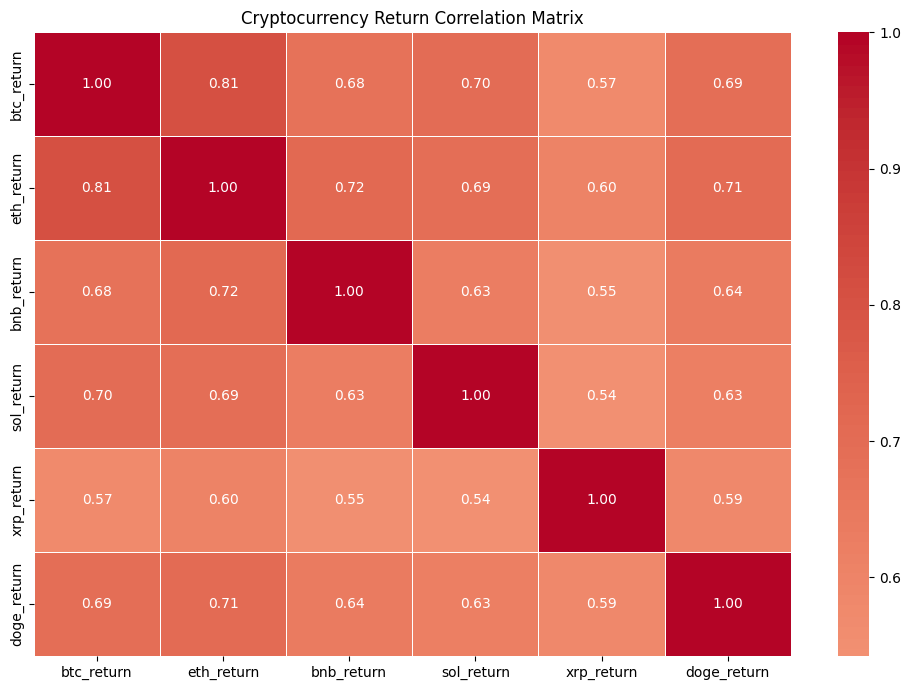

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    crypto_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Cryptocurrency Return Correlation Matrix")
plt.tight_layout()
plt.show()

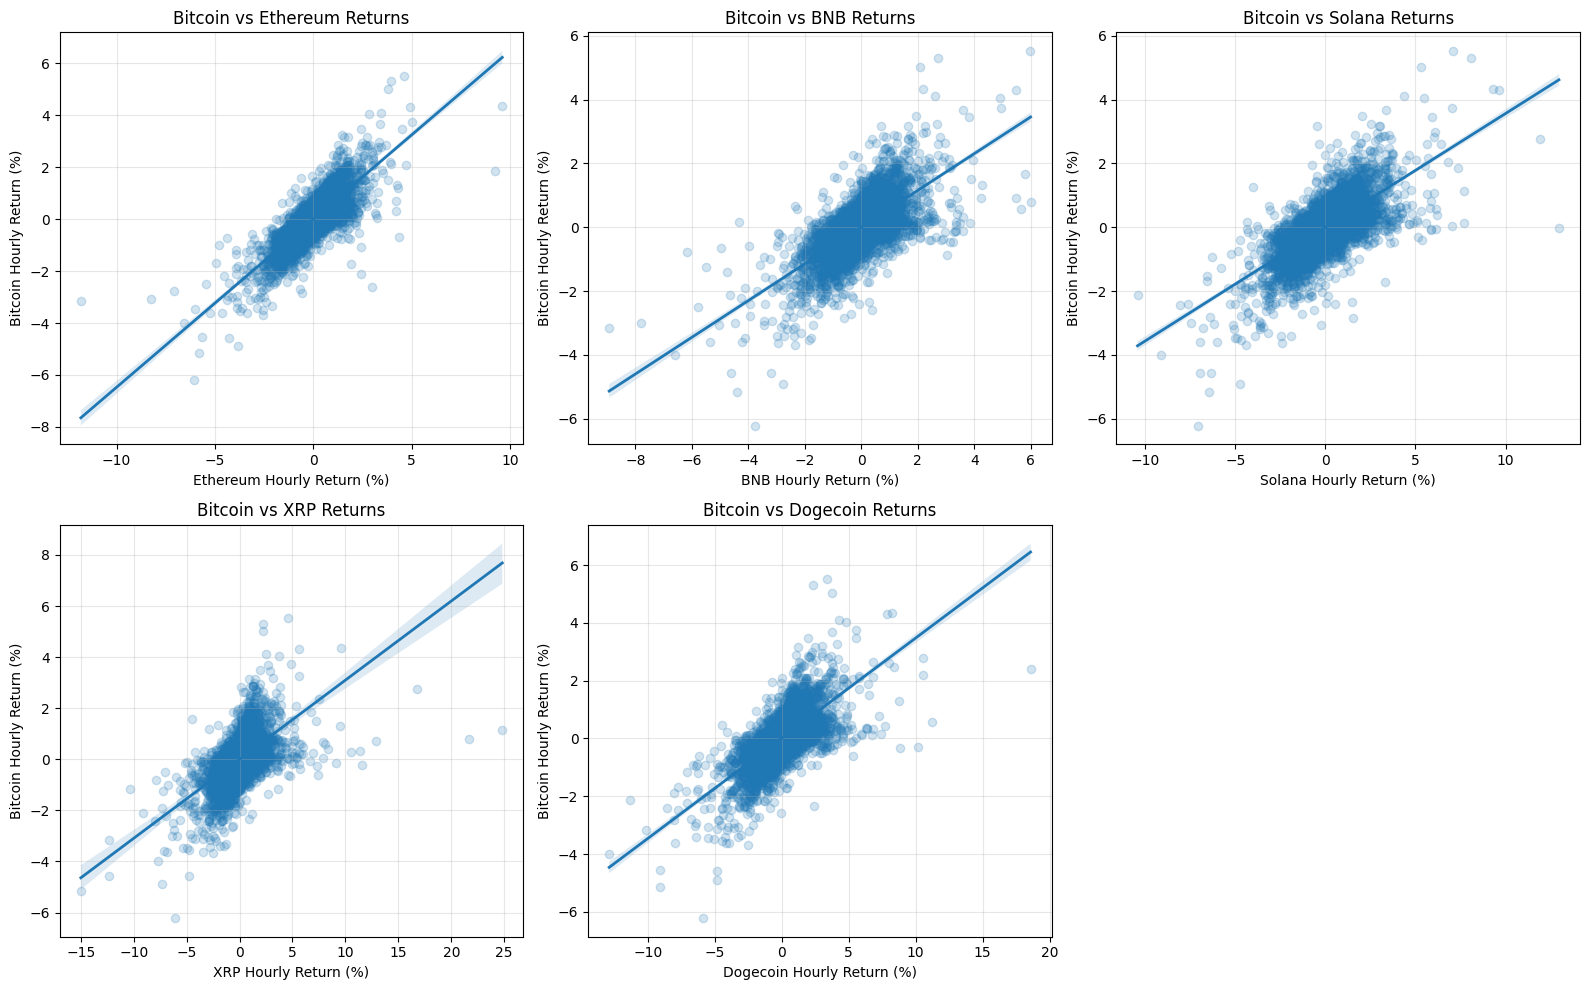

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

cryptos = [
    ("eth_return", "Ethereum"),
    ("bnb_return", "BNB"),
    ("sol_return", "Solana"),
    ("xrp_return", "XRP"),
    ("doge_return", "Dogecoin")
]

for ax, (column, name) in zip(axes.flatten(), cryptos):

    sns.regplot(
        data=data_ml,
        x=column,
        y="btc_return",
        scatter_kws={"alpha": 0.2},
        line_kws={"linewidth": 2},
        ax=ax
    )

    ax.set_title(f"Bitcoin vs {name} Returns")
    ax.set_xlabel(f"{name} Hourly Return (%)")
    ax.set_ylabel("Bitcoin Hourly Return (%)")
    ax.grid(alpha=0.3)

# Hide unused subplot
axes.flatten()[-1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# 28 — Overall Market Factor Correlation Analysis

factor_features = [
    "btc_return",
    "btc_volatility_6h",
    "btc_volatility_24h",
    "btc_volume_change_pct",

    "eth_return",
    "bnb_return",
    "sol_return",
    "xrp_return",
    "doge_return",

    "nasdaq_return",
    "sp500_return",
    "dow_return",
    "russell_return",

    "vix_change_pct",
    "fear_greed_change",

    "btc_dominance_change",
    "altcoin_market_cap_change",
    "open_interest_change_pct"
]

factor_corr = data_ml[factor_features].corr()

print("Overall Market Factor Correlation Matrix:")
print(factor_corr.round(3))

Overall Market Factor Correlation Matrix:
                           btc_return  btc_volatility_6h  btc_volatility_24h  \
btc_return                      1.000              0.007               0.012   
btc_volatility_6h               0.007              1.000               0.683   
btc_volatility_24h              0.012              0.683               1.000   
btc_volume_change_pct          -0.023              0.024              -0.017   
eth_return                      0.809             -0.002               0.008   
bnb_return                      0.679              0.000               0.013   
sol_return                      0.698              0.010               0.014   
xrp_return                      0.571              0.006               0.012   
doge_return                     0.689              0.003               0.014   
nasdaq_return                   0.098             -0.024              -0.008   
sp500_return                    0.090             -0.022              -0.005  

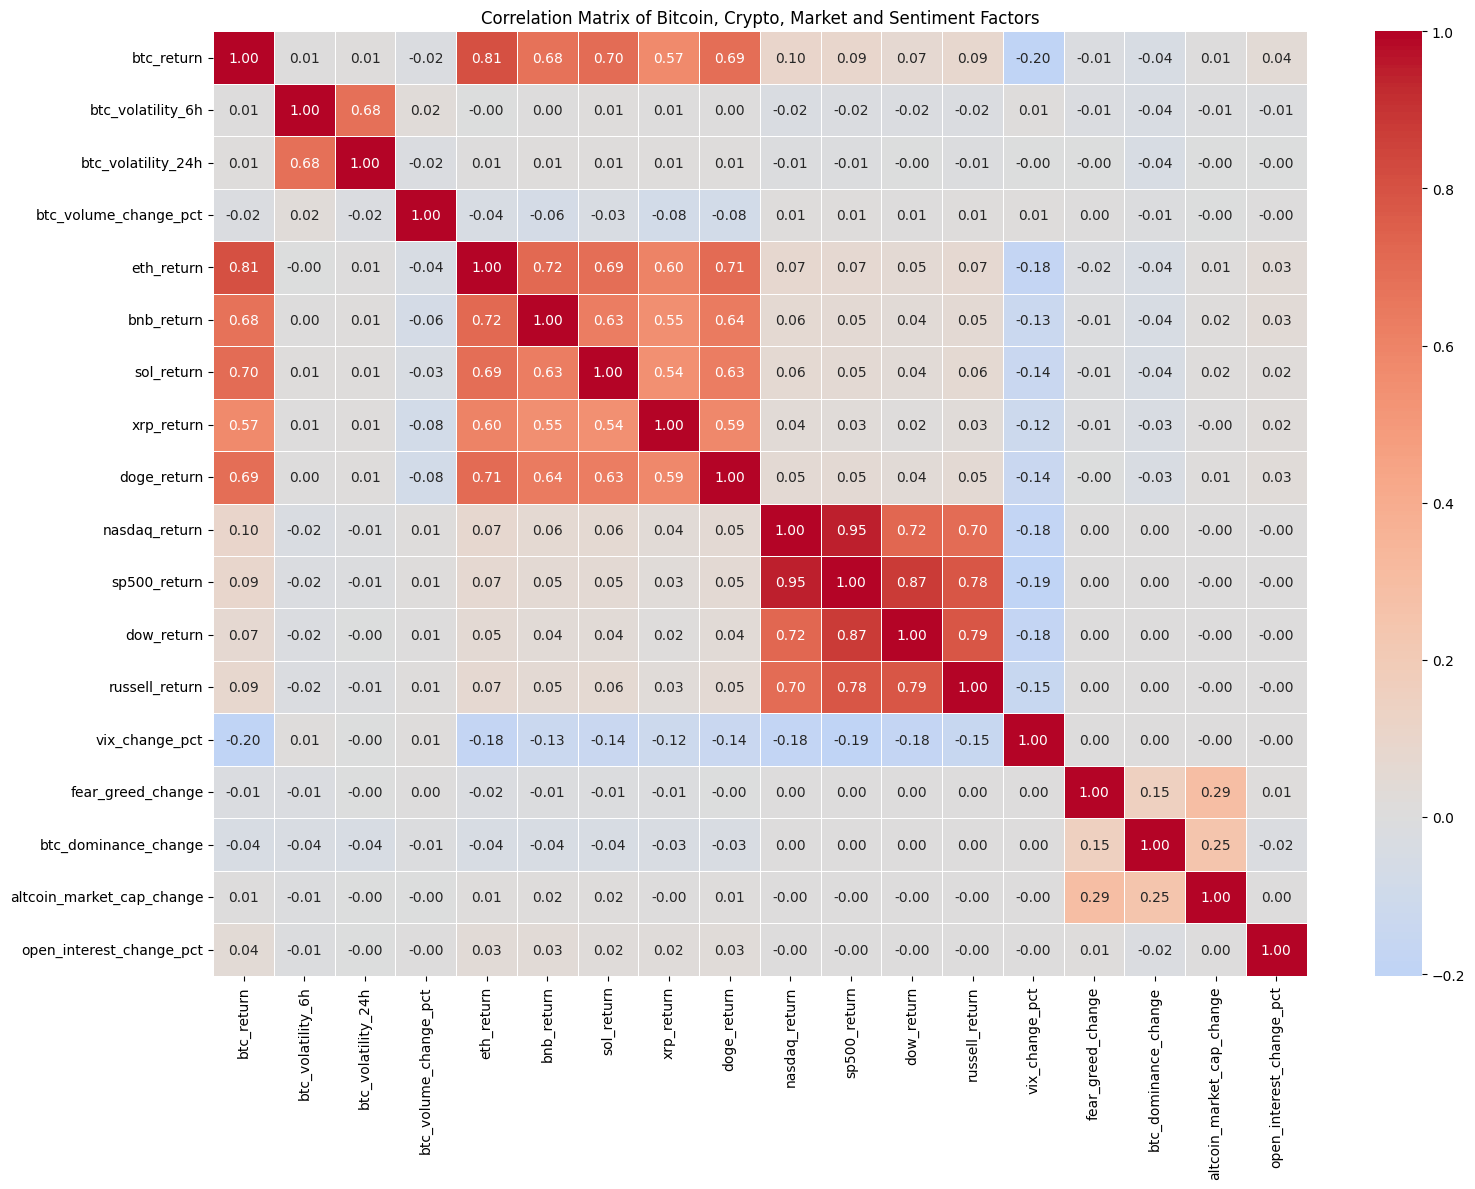

In [ ]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    factor_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.4
)

plt.title("Correlation Matrix of Bitcoin, Crypto, Market and Sentiment Factors")
plt.tight_layout()
plt.show()

In [ ]:
btc_factor_corr = (
    factor_corr["btc_return"]
    .drop("btc_return")
    .sort_values(key=abs, ascending=False)
)

print("Factors Ranked by Absolute Correlation with Bitcoin Returns:")
print(btc_factor_corr.round(4))

Factors Ranked by Absolute Correlation with Bitcoin Returns:
eth_return                   0.8091
sol_return                   0.6983
doge_return                  0.6893
bnb_return                   0.6791
xrp_return                   0.5712
vix_change_pct              -0.2022
nasdaq_return                0.0984
sp500_return                 0.0900
russell_return               0.0881
dow_return                   0.0694
open_interest_change_pct     0.0420
btc_dominance_change        -0.0391
btc_volume_change_pct       -0.0232
fear_greed_change           -0.0149
btc_volatility_24h           0.0117
altcoin_market_cap_change    0.0082
btc_volatility_6h            0.0069
Name: btc_return, dtype: float64


In [ ]:
from scipy.stats import ttest_ind

# Separate BTC returns based on VIX movement
vix_decreasing = data_ml.loc[
    data_ml["vix_change_pct"] < 0, "btc_return"
].dropna()

vix_increasing = data_ml.loc[
    data_ml["vix_change_pct"] > 0, "btc_return"
].dropna()

# Independent samples t-test
t_stat, p_value = ttest_ind(
    vix_decreasing,
    vix_increasing,
    equal_var=False
)

print("VIX Rising vs Falling - Independent T-Test")
print("-------------------------------------------")
print(f"VIX Decreasing Mean BTC Return: {vix_decreasing.mean():.4f}%")
print(f"VIX Increasing Mean BTC Return: {vix_increasing.mean():.4f}%")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("\nResult: Statistically significant difference.")
else:
    print("\nResult: No statistically significant difference.")

VIX Rising vs Falling - Independent T-Test
-------------------------------------------
VIX Decreasing Mean BTC Return: 0.1200%
VIX Increasing Mean BTC Return: -0.1242%
T-statistic: 16.4268
P-value: 0.000000

Result: Statistically significant difference.


In [ ]:
from scipy.stats import f_oneway

# Get BTC returns for each sentiment category
extreme_fear = data_ml.loc[
    data_ml["sentiment_category"] == "Extreme Fear",
    "btc_return"
].dropna()

fear = data_ml.loc[
    data_ml["sentiment_category"] == "Fear",
    "btc_return"
].dropna()

neutral = data_ml.loc[
    data_ml["sentiment_category"] == "Neutral",
    "btc_return"
].dropna()

greed = data_ml.loc[
    data_ml["sentiment_category"] == "Greed",
    "btc_return"
].dropna()

extreme_greed = data_ml.loc[
    data_ml["sentiment_category"] == "Extreme Greed",
    "btc_return"
].dropna()

# Perform one-way ANOVA
f_stat, p_value = f_oneway(
    extreme_fear,
    fear,
    neutral,
    greed,
    extreme_greed
)

print("One-Way ANOVA: Bitcoin Returns Across Sentiment Categories")
print("-----------------------------------------------------------")

print(f"Extreme Fear Mean:   {extreme_fear.mean():.4f}%")
print(f"Fear Mean:           {fear.mean():.4f}%")
print(f"Neutral Mean:        {neutral.mean():.4f}%")
print(f"Greed Mean:          {greed.mean():.4f}%")
print(f"Extreme Greed Mean:  {extreme_greed.mean():.4f}%")

print("\nANOVA Results")
print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("\nResult: Statistically significant difference among sentiment groups.")
else:
    print("\nResult: No statistically significant difference among sentiment groups.")

One-Way ANOVA: Bitcoin Returns Across Sentiment Categories
-----------------------------------------------------------
Extreme Fear Mean:   0.0429%
Fear Mean:           0.0071%
Neutral Mean:        -0.0009%
Greed Mean:          0.0124%
Extreme Greed Mean:  -0.0043%

ANOVA Results
F-statistic: 1.2706
P-value: 0.278994

Result: No statistically significant difference among sentiment groups.


In [ ]:
# ==========================================
# STEP 23.1 - Prepare Data for Linear Regression
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Features
X = data_ml[engineered_features].copy()

# Target: next-hour Bitcoin return
y = data_ml["next_hour_return"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Feature matrix shape: (17444, 34)
Target shape: (17444,)

Features:
['btc_return', 'btc_price_range', 'btc_range_pct', 'btc_volume_change_pct', 'btc_volatility_6h', 'btc_volatility_24h', 'btc_ma_6h', 'btc_ma_24h', 'btc_ma_72h', 'btc_ma_24h_diff_pct', 'btc_price_lag_1h', 'btc_price_lag_3h', 'btc_price_lag_6h', 'btc_return_lag_1h', 'btc_return_lag_3h', 'eth_return', 'bnb_return', 'sol_return', 'xrp_return', 'doge_return', 'nasdaq_return', 'sp500_return', 'dow_return', 'russell_return', 'vix_change_pct', 'btc_dominance_change', 'altcoin_market_cap_change', 'fear_greed_change', 'bitcoin_trend_change', 'buy_crypto_trend_change', 'open_interest_change_pct', 'hour', 'day_of_week', 'is_weekend']

Target:
next_hour_return


In [ ]:
# ==========================================
# STEP 23.2 - Chronological Train/Test Split
# ==========================================

split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining period:")
print(data_ml["timestamp"].iloc[:split_index].min())
print("to")
print(data_ml["timestamp"].iloc[split_index - 1])

print("\nTesting period:")
print(data_ml["timestamp"].iloc[split_index])
print("to")
print(data_ml["timestamp"].iloc[-1])

Training samples: 13955
Testing samples: 3489

Training period:
2023-04-11 23:00:00
to
2024-11-13 09:00:00

Testing period:
2024-11-13 10:00:00
to
2025-04-07 18:00:00


In [ ]:
# ==========================================
# STEP 23.3 - Train Linear Regression
# ==========================================

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

# Predictions
y_pred = linear_model.predict(X_test)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [ ]:
# ==========================================
# STEP 23.4 - Regression Evaluation
# ==========================================

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Linear Regression Performance")
print("--------------------------------")
print(f"MAE  : {mae:.6f}%")
print(f"RMSE : {rmse:.6f}%")
print(f"R²   : {r2:.6f}")

Linear Regression Performance
--------------------------------
MAE  : 0.395919%
RMSE : 0.597574%
R²   : 0.002489


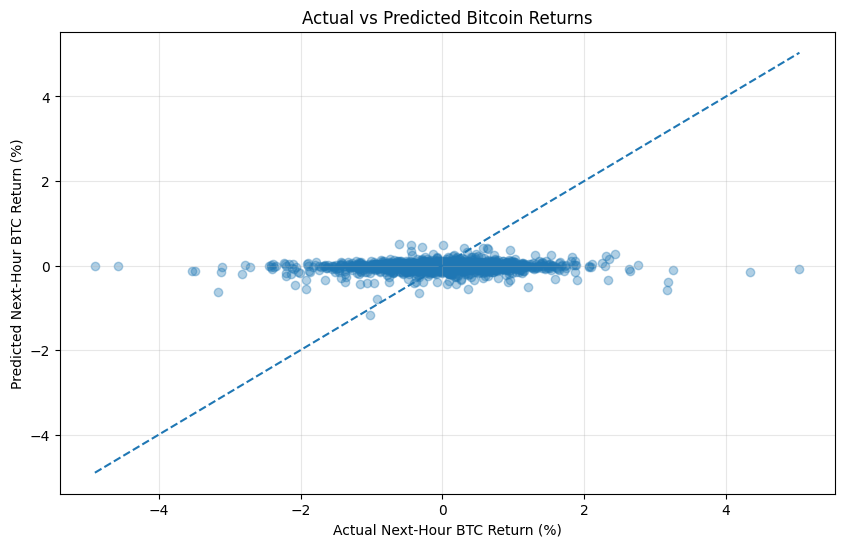

In [ ]:
# ==========================================
# STEP 23.5 - Actual vs Predicted
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.35
)

# Perfect prediction line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Next-Hour BTC Return (%)")
plt.ylabel("Predicted Next-Hour BTC Return (%)")
plt.title("Actual vs Predicted Bitcoin Returns")

plt.grid(alpha=0.3)
plt.show()

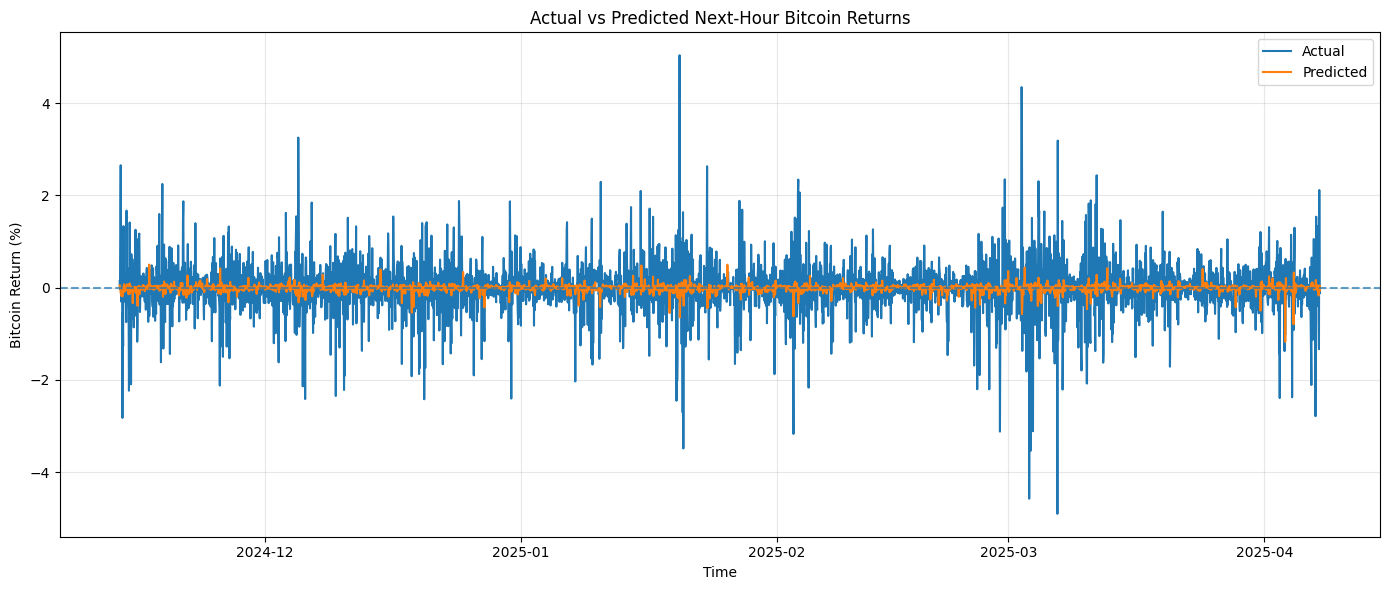

In [ ]:
# ==========================================
# STEP 23.6 - Actual vs Predicted Over Time
# ==========================================

results = pd.DataFrame({
    "timestamp": data_ml["timestamp"].iloc[split_index:].values,
    "actual_return": y_test.values,
    "predicted_return": y_pred
})

plt.figure(figsize=(14, 6))

plt.plot(
    results["timestamp"],
    results["actual_return"],
    label="Actual"
)

plt.plot(
    results["timestamp"],
    results["predicted_return"],
    label="Predicted"
)

plt.axhline(
    0,
    linestyle="--",
    alpha=0.7
)

plt.xlabel("Time")
plt.ylabel("Bitcoin Return (%)")
plt.title("Actual vs Predicted Next-Hour Bitcoin Returns")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# STEP 23.7 - Regression Coefficients
# ==========================================

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": linear_model.coef_
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

print("Regression Coefficients Ranked by Absolute Magnitude:")
print(coefficients.to_string(index=False))

Regression Coefficients Ranked by Absolute Magnitude:
                  Feature  Coefficient  Absolute_Coefficient
             sp500_return    -0.730585              0.730585
            nasdaq_return     0.433035              0.433035
               dow_return     0.354043              0.354043
           russell_return     0.114171              0.114171
            btc_range_pct     0.087031              0.087031
               btc_return    -0.072793              0.072793
               eth_return    -0.050629              0.050629
               is_weekend     0.029682              0.029682
        btc_return_lag_3h     0.029482              0.029482
               bnb_return     0.028162              0.028162
 open_interest_change_pct     0.027827              0.027827
              doge_return     0.023766              0.023766
altcoin_market_cap_change     0.023010              0.023010
       btc_volatility_24h     0.020406              0.020406
        btc_volatility_6h     0

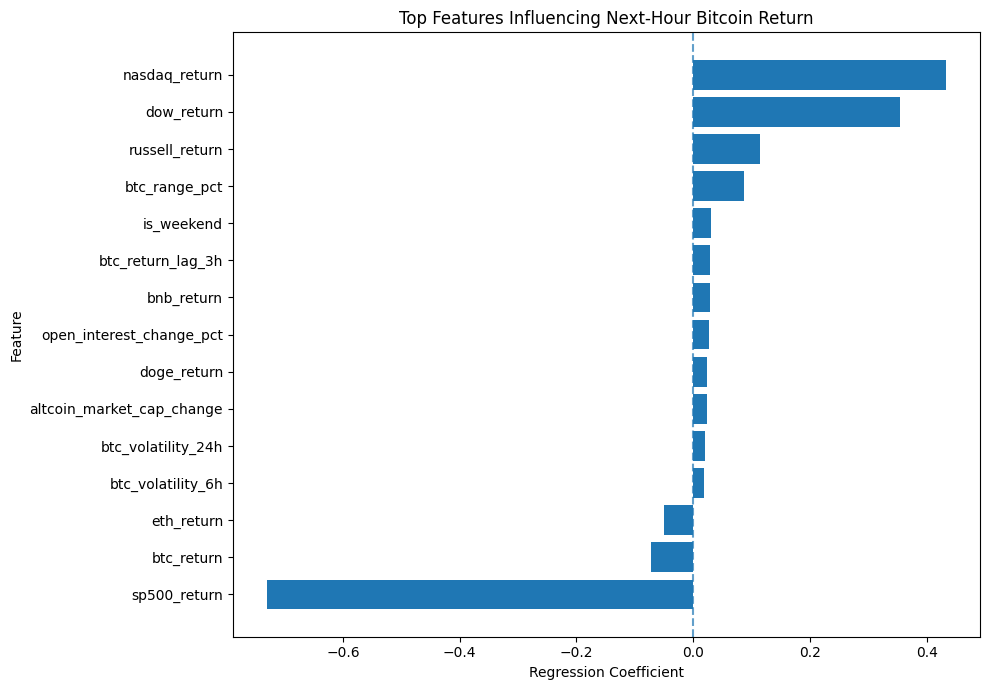

In [ ]:
# ==========================================
# Regression Coefficient Visualization
# ==========================================

top_coefficients = coefficients.head(15).sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_coefficients["Feature"],
    top_coefficients["Coefficient"]
)

plt.axvline(
    0,
    linestyle="--",
    alpha=0.7
)

plt.xlabel("Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top Features Influencing Next-Hour Bitcoin Return")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import numpy as np

# Features and target
X = data_ml[engineered_features].copy()
y = data_ml["btc_direction"].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Percentage:")
print(y.value_counts(normalize=True).mul(100).round(2))

Feature shape: (17444, 34)
Target shape: (17444,)

Target Distribution:
btc_direction
1    8886
0    8558
Name: count, dtype: int64

Target Percentage:
btc_direction
1    50.94
0    49.06
Name: proportion, dtype: float64


In [ ]:
# 80% training, 20% testing
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining period:")
print(data_ml["timestamp"].iloc[0], "to", data_ml["timestamp"].iloc[split_index - 1])

print("\nTesting period:")
print(data_ml["timestamp"].iloc[split_index], "to", data_ml["timestamp"].iloc[-1])

Training samples: 13955
Testing samples : 3489

Training period:
2023-04-11 23:00:00 to 2024-11-13 09:00:00

Testing period:
2024-11-13 10:00:00 to 2025-04-07 18:00:00


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [ ]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [ ]:
# Predictions
y_pred = logistic_model.predict(X_test_scaled)

# Probability of Bitcoin going UP
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

Logistic Regression Performance
--------------------------------
Accuracy  : 0.5285
Precision : 0.5310
Recall    : 0.5777
F1-Score  : 0.5534
ROC-AUC   : 0.5421


In [ ]:
print("\nClassification Report")
print("---------------------")

print(classification_report(
    y_test,
    y_pred,
    target_names=["DOWN", "UP"]
))


Classification Report
---------------------
              precision    recall  f1-score   support

        DOWN       0.53      0.48      0.50      1725
          UP       0.53      0.58      0.55      1764

    accuracy                           0.53      3489
   macro avg       0.53      0.53      0.53      3489
weighted avg       0.53      0.53      0.53      3489



In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 825  900]
 [ 745 1019]]


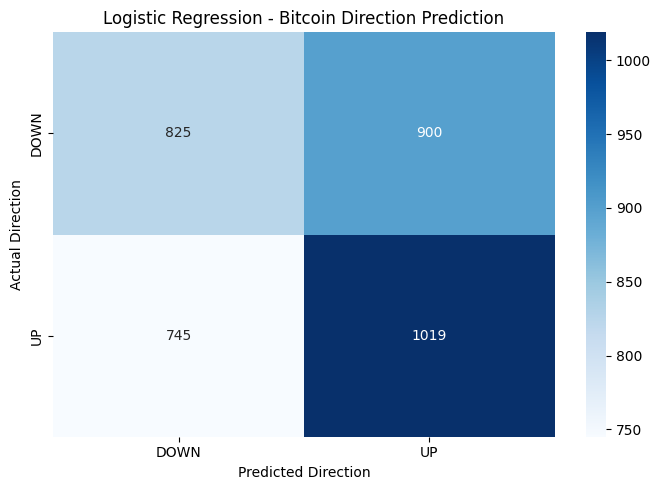

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["DOWN", "UP"],
    yticklabels=["DOWN", "UP"]
)

plt.title("Logistic Regression - Bitcoin Direction Prediction")
plt.xlabel("Predicted Direction")
plt.ylabel("Actual Direction")

plt.tight_layout()
plt.show()

In [ ]:
logistic_coefficients = pd.DataFrame({
    "Feature": engineered_features,
    "Coefficient": logistic_model.coef_[0]
})

logistic_coefficients["Absolute_Coefficient"] = (
    logistic_coefficients["Coefficient"].abs()
)

logistic_coefficients = logistic_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

print("Logistic Regression Feature Importance")
print("---------------------------------------")

print(logistic_coefficients.to_string(index=False))

Logistic Regression Feature Importance
---------------------------------------
                  Feature  Coefficient  Absolute_Coefficient
             sp500_return    -0.148990              0.148990
               btc_return    -0.142790              0.142790
            nasdaq_return     0.129358              0.129358
               dow_return     0.077543              0.077543
           russell_return     0.073453              0.073453
          btc_price_range    -0.071147              0.071147
               eth_return    -0.069499              0.069499
        btc_volatility_6h     0.065261              0.065261
 open_interest_change_pct     0.061243              0.061243
               btc_ma_72h    -0.052090              0.052090
              doge_return     0.045142              0.045142
            btc_range_pct     0.044213              0.044213
         btc_price_lag_6h     0.038134              0.038134
     btc_dominance_change     0.035896              0.035896
    bt

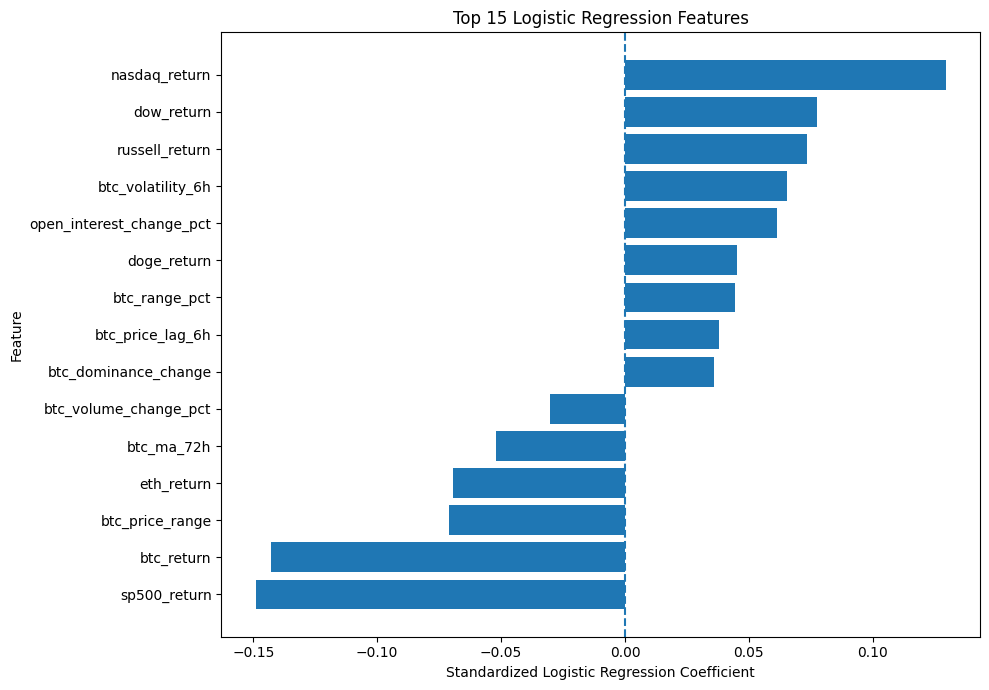

In [ ]:
top_features = logistic_coefficients.head(15).sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linestyle="--")

plt.title("Top 15 Logistic Regression Features")
plt.xlabel("Standardized Logistic Regression Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [ ]:
logistic_coefficients.to_csv(
    "bitcoin_logistic_regression_coefficients.csv",
    index=False
)

print("Logistic regression coefficients saved successfully.")

Logistic regression coefficients saved successfully.


In [ ]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully.")

SVM model trained successfully.


In [ ]:
y_svm_pred = svm_model.predict(X_test_scaled)

y_svm_prob = svm_model.predict_proba(X_test_scaled)[:, 1]

print("SVM predictions completed.")

SVM predictions completed.


In [ ]:
svm_accuracy = accuracy_score(y_test, y_svm_pred)
svm_precision = precision_score(y_test, y_svm_pred)
svm_recall = recall_score(y_test, y_svm_pred)
svm_f1 = f1_score(y_test, y_svm_pred)
svm_roc_auc = roc_auc_score(y_test, y_svm_prob)

print("SVM Classification Performance")
print("--------------------------------")
print(f"Accuracy  : {svm_accuracy:.4f}")
print(f"Precision : {svm_precision:.4f}")
print(f"Recall    : {svm_recall:.4f}")
print(f"F1-Score  : {svm_f1:.4f}")
print(f"ROC-AUC   : {svm_roc_auc:.4f}")

SVM Classification Performance
--------------------------------
Accuracy  : 0.5133
Precision : 0.5145
Recall    : 0.6638
F1-Score  : 0.5797
ROC-AUC   : 0.5141


In [ ]:
print("\nSVM Classification Report")
print("--------------------------")

print(classification_report(
    y_test,
    y_svm_pred,
    target_names=["DOWN", "UP"]
))


SVM Classification Report
--------------------------
              precision    recall  f1-score   support

        DOWN       0.51      0.36      0.42      1725
          UP       0.51      0.66      0.58      1764

    accuracy                           0.51      3489
   macro avg       0.51      0.51      0.50      3489
weighted avg       0.51      0.51      0.50      3489



In [ ]:
svm_cm = confusion_matrix(y_test, y_svm_pred)

print("SVM Confusion Matrix:")
print(svm_cm)

SVM Confusion Matrix:
[[ 620 1105]
 [ 593 1171]]


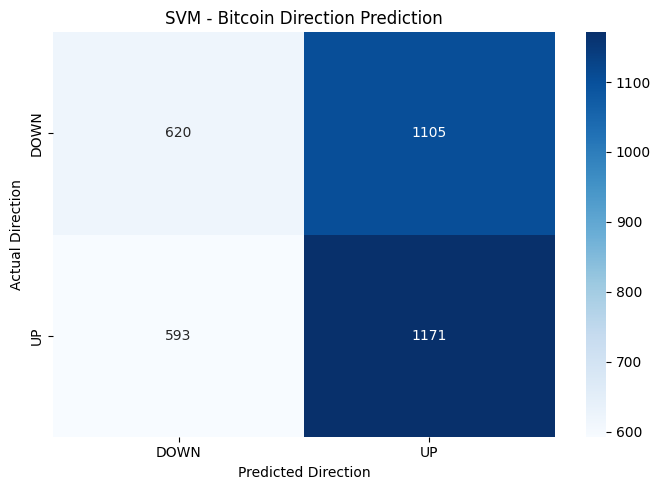

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["DOWN", "UP"],
    yticklabels=["DOWN", "UP"]
)

plt.title("SVM - Bitcoin Direction Prediction")
plt.xlabel("Predicted Direction")
plt.ylabel("Actual Direction")

plt.tight_layout()
plt.show()

In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM"
    ],
    "Accuracy": [
        accuracy,
        svm_accuracy
    ],
    "Precision": [
        precision,
        svm_precision
    ],
    "Recall": [
        recall,
        svm_recall
    ],
    "F1-Score": [
        f1,
        svm_f1
    ],
    "ROC-AUC": [
        roc_auc,
        svm_roc_auc
    ]
})

print("Classification Model Comparison")
print("--------------------------------")
print(model_comparison.round(4))

Classification Model Comparison
--------------------------------
                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Logistic Regression    0.5285     0.5310  0.5777    0.5534   0.5421
1                  SVM    0.5133     0.5145  0.6638    0.5797   0.5141


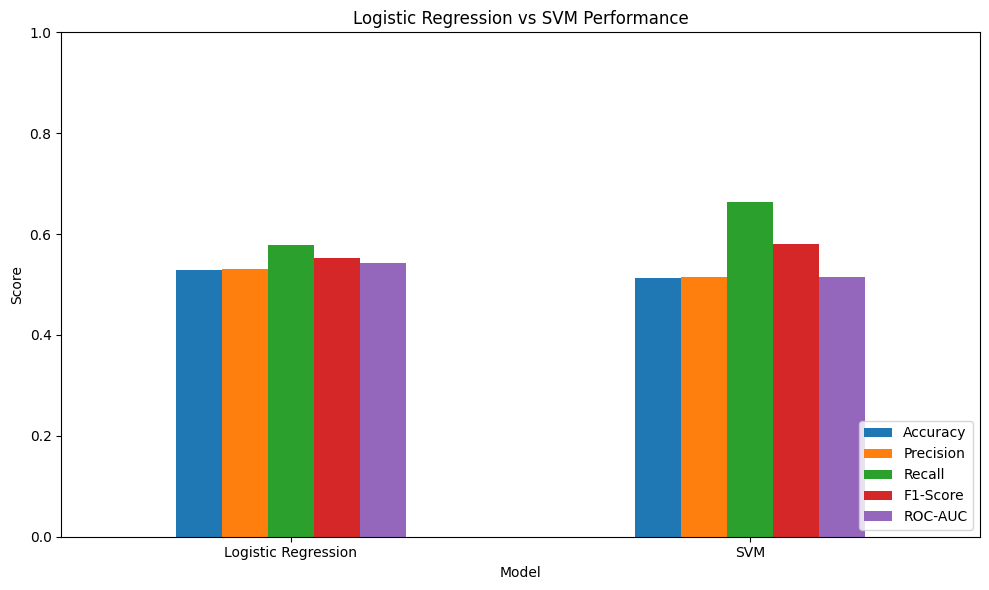

In [ ]:
model_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Logistic Regression vs SVM Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    subsample=0.8,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully.")

Gradient Boosting model trained successfully.


In [ ]:
y_gb_pred = gb_model.predict(X_test)

y_gb_prob = gb_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting predictions completed.")

Gradient Boosting predictions completed.


In [ ]:
gb_accuracy = accuracy_score(y_test, y_gb_pred)
gb_precision = precision_score(y_test, y_gb_pred)
gb_recall = recall_score(y_test, y_gb_pred)
gb_f1 = f1_score(y_test, y_gb_pred)
gb_roc_auc = roc_auc_score(y_test, y_gb_prob)

print("Gradient Boosting Performance")
print("--------------------------------")
print(f"Accuracy  : {gb_accuracy:.4f} ({gb_accuracy*100:.2f}%)")
print(f"Precision : {gb_precision:.4f}")
print(f"Recall    : {gb_recall:.4f}")
print(f"F1-Score  : {gb_f1:.4f}")
print(f"ROC-AUC   : {gb_roc_auc:.4f}")

Gradient Boosting Performance
--------------------------------
Accuracy  : 0.5159 (51.59%)
Precision : 0.5143
Recall    : 0.7636
F1-Score  : 0.6146
ROC-AUC   : 0.5270


In [ ]:
print("\nGradient Boosting Classification Report")
print("-----------------------------------------")

print(classification_report(
    y_test,
    y_gb_pred,
    target_names=["DOWN", "UP"]
))


Gradient Boosting Classification Report
-----------------------------------------
              precision    recall  f1-score   support

        DOWN       0.52      0.26      0.35      1725
          UP       0.51      0.76      0.61      1764

    accuracy                           0.52      3489
   macro avg       0.52      0.51      0.48      3489
weighted avg       0.52      0.52      0.48      3489



In [ ]:
gb_cm = confusion_matrix(y_test, y_gb_pred)

print("Gradient Boosting Confusion Matrix:")
print(gb_cm)

Gradient Boosting Confusion Matrix:
[[ 453 1272]
 [ 417 1347]]


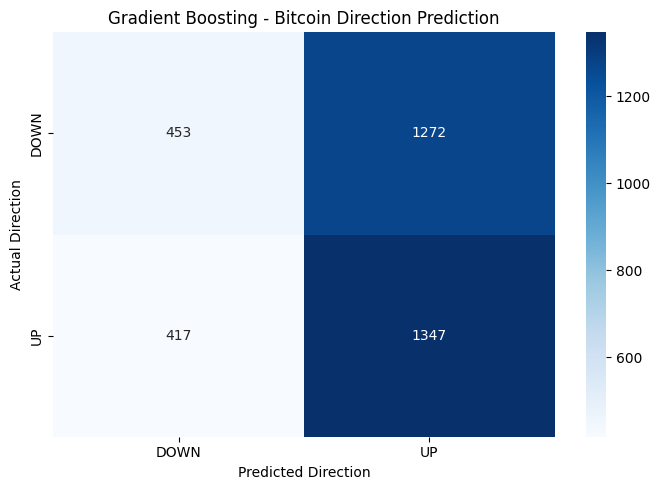

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    gb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["DOWN", "UP"],
    yticklabels=["DOWN", "UP"]
)

plt.title("Gradient Boosting - Bitcoin Direction Prediction")
plt.xlabel("Predicted Direction")
plt.ylabel("Actual Direction")

plt.tight_layout()
plt.show()

In [ ]:
gb_importance = pd.DataFrame({
    "Feature": engineered_features,
    "Importance": gb_model.feature_importances_
})

gb_importance = gb_importance.sort_values(
    "Importance",
    ascending=False
)

print("Gradient Boosting Feature Importance")
print("-------------------------------------")

print(gb_importance.to_string(index=False))

Gradient Boosting Feature Importance
-------------------------------------
                  Feature  Importance
               btc_return    0.069595
        btc_return_lag_1h    0.066381
    btc_volume_change_pct    0.059957
        btc_volatility_6h    0.057892
      btc_ma_24h_diff_pct    0.057697
               eth_return    0.050514
       btc_volatility_24h    0.049579
        btc_return_lag_3h    0.047451
               xrp_return    0.047220
               sol_return    0.043690
            btc_range_pct    0.042268
               bnb_return    0.040816
              doge_return    0.035378
           russell_return    0.034441
           vix_change_pct    0.033880
            nasdaq_return    0.028543
                     hour    0.028378
          btc_price_range    0.026652
               btc_ma_72h    0.021789
         btc_price_lag_3h    0.018183
               dow_return    0.017377
         btc_price_lag_6h    0.016930
               btc_ma_24h    0.016611
 open_interes

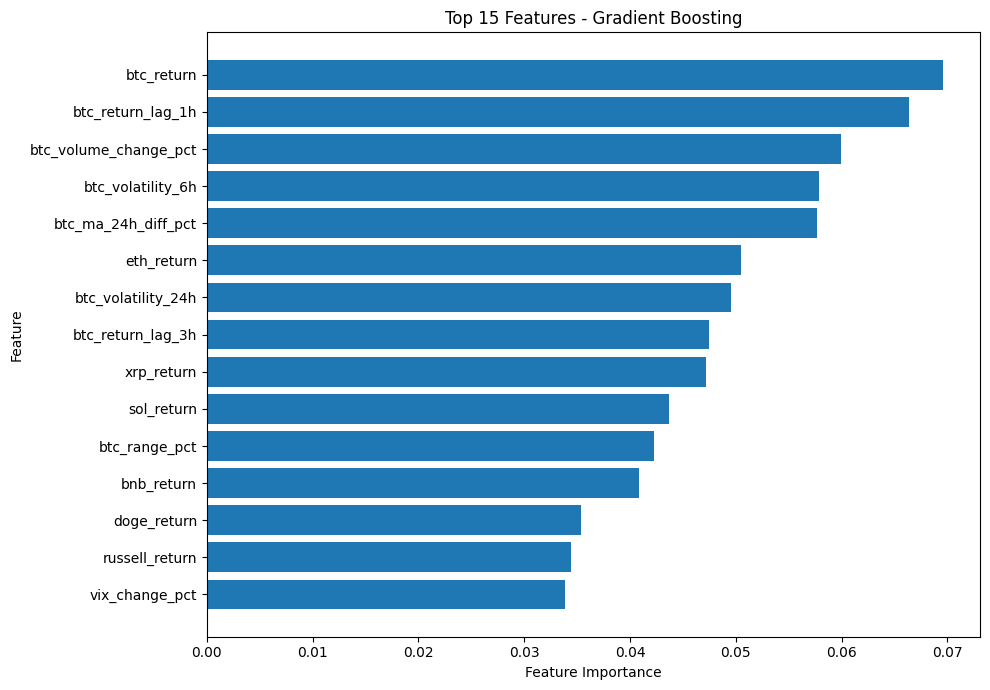

In [ ]:
top_gb_features = gb_importance.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_gb_features["Feature"],
    top_gb_features["Importance"]
)

plt.title("Top 15 Features - Gradient Boosting")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [ ]:
classification_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy,
        svm_accuracy,
        gb_accuracy
    ],
    "Precision": [
        precision,
        svm_precision,
        gb_precision
    ],
    "Recall": [
        recall,
        svm_recall,
        gb_recall
    ],
    "F1-Score": [
        f1,
        svm_f1,
        gb_f1
    ],
    "ROC-AUC": [
        roc_auc,
        svm_roc_auc,
        gb_roc_auc
    ]
})

print("CLASSIFICATION MODEL COMPARISON")
print("--------------------------------")
print(classification_comparison.round(4))

CLASSIFICATION MODEL COMPARISON
--------------------------------
                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Logistic Regression    0.5285     0.5310  0.5777    0.5534   0.5421
1                  SVM    0.5133     0.5145  0.6638    0.5797   0.5141
2    Gradient Boosting    0.5159     0.5143  0.7636    0.6146   0.5270


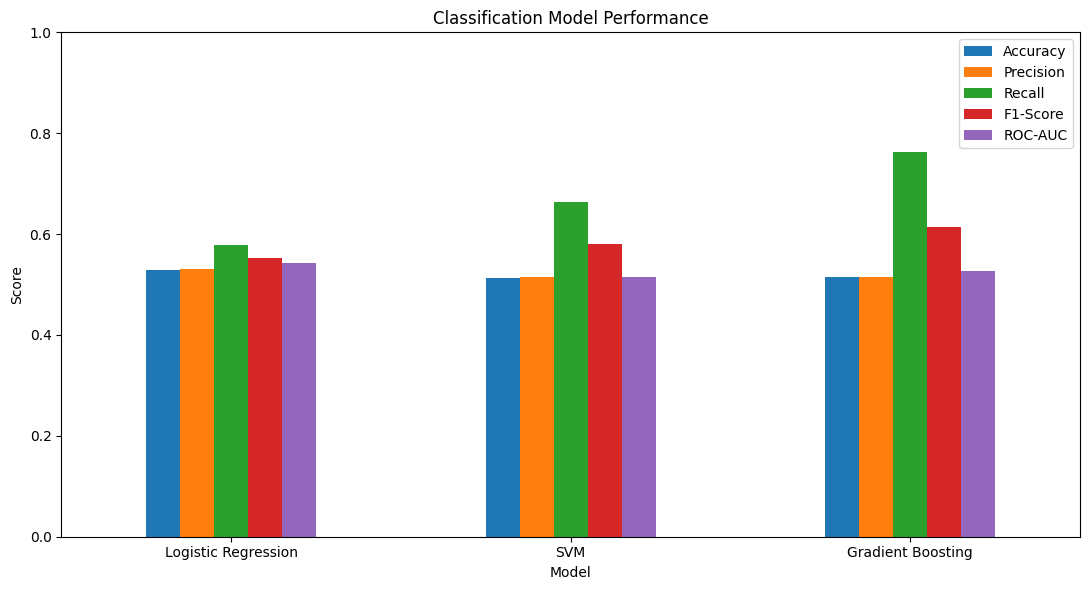

In [ ]:
classification_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Classification Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# Split the existing 80% training data chronologically
val_split = int(len(X_train) * 0.80)

X_train_gb = X_train.iloc[:val_split]
X_val_gb = X_train.iloc[val_split:]

y_train_gb = y_train.iloc[:val_split]
y_val_gb = y_train.iloc[val_split:]

print("Gradient Boosting Training:", len(X_train_gb))
print("Validation:", len(X_val_gb))
print("Final Test:", len(X_test))

Gradient Boosting Training: 11164
Validation: 2791
Final Test: 3489


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb_configs = [
    {
        "n_estimators": 300,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_samples_leaf": 10,
        "subsample": 0.8
    },
    {
        "n_estimators": 500,
        "learning_rate": 0.03,
        "max_depth": 3,
        "min_samples_leaf": 10,
        "subsample": 0.8
    },
    {
        "n_estimators": 700,
        "learning_rate": 0.02,
        "max_depth": 3,
        "min_samples_leaf": 15,
        "subsample": 0.8
    },
    {
        "n_estimators": 500,
        "learning_rate": 0.02,
        "max_depth": 4,
        "min_samples_leaf": 15,
        "subsample": 0.7
    },
    {
        "n_estimators": 800,
        "learning_rate": 0.015,
        "max_depth": 4,
        "min_samples_leaf": 20,
        "subsample": 0.8
    }
]

results = []

for i, params in enumerate(gb_configs):

    model = GradientBoostingClassifier(
        **params,
        random_state=42
    )

    model.fit(X_train_gb, y_train_gb)

    val_pred = model.predict(X_val_gb)
    val_prob = model.predict_proba(X_val_gb)[:, 1]

    results.append({
        "Configuration": i + 1,
        "Accuracy": accuracy_score(y_val_gb, val_pred),
        "Precision": precision_score(y_val_gb, val_pred),
        "Recall": recall_score(y_val_gb, val_pred),
        "F1": f1_score(y_val_gb, val_pred),
        "ROC_AUC": roc_auc_score(y_val_gb, val_prob)
    })

gb_tuning_results = pd.DataFrame(results)

print("Gradient Boosting Hyperparameter Results")
print("-----------------------------------------")
print(gb_tuning_results.round(4))

Gradient Boosting Hyperparameter Results
-----------------------------------------
   Configuration  Accuracy  Precision  Recall      F1  ROC_AUC
0              1    0.5471     0.5477  0.6051  0.5750   0.5556
1              2    0.5364     0.5384  0.5902  0.5631   0.5538
2              3    0.5439     0.5435  0.6192  0.5789   0.5552
3              4    0.5439     0.5445  0.6058  0.5735   0.5549
4              5    0.5442     0.5446  0.6093  0.5752   0.5525


In [ ]:
best_config_number = gb_tuning_results.loc[
    gb_tuning_results["Accuracy"].idxmax(),
    "Configuration"
]

best_config = gb_configs[int(best_config_number) - 1]

print("Best Configuration:")
print(best_config)

Best Configuration:
{'n_estimators': 300, 'learning_rate': 0.03, 'max_depth': 2, 'min_samples_leaf': 10, 'subsample': 0.8}


In [ ]:
best_gb = GradientBoostingClassifier(
    **best_config,
    random_state=42
)

best_gb.fit(X_train_gb, y_train_gb)

val_prob = best_gb.predict_proba(X_val_gb)[:, 1]

In [ ]:
threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.01):

    val_threshold_pred = (
        val_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val_gb,
            val_threshold_pred
        ),
        "Precision": precision_score(
            y_val_gb,
            val_threshold_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val_gb,
            val_threshold_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_val_gb,
            val_threshold_pred,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

print(
    threshold_results
    .sort_values("Accuracy", ascending=False)
    .head(10)
    .round(4)
)

    Threshold  Accuracy  Precision  Recall      F1
20       0.50    0.5471     0.5477  0.6051  0.5750
22       0.52    0.5453     0.5599  0.4763  0.5147
23       0.53    0.5407     0.5620  0.4204  0.4810
21       0.51    0.5396     0.5460  0.5379  0.5419
19       0.49    0.5382     0.5363  0.6490  0.5873
18       0.48    0.5367     0.5320  0.7056  0.6066
24       0.54    0.5346     0.5639  0.3560  0.4364
25       0.55    0.5299     0.5695  0.2930  0.3869
17       0.47    0.5296     0.5249  0.7452  0.6160
26       0.56    0.5242     0.5724  0.2378  0.3360


In [ ]:
best_threshold_row = threshold_results.loc[
    threshold_results["Accuracy"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]

print("Best Threshold:", round(best_threshold, 2))
print("Validation Accuracy:",
      round(best_threshold_row["Accuracy"], 4))
print("Validation Precision:",
      round(best_threshold_row["Precision"], 4))
print("Validation Recall:",
      round(best_threshold_row["Recall"], 4))
print("Validation F1:",
      round(best_threshold_row["F1"], 4))

Best Threshold: 0.5
Validation Accuracy: 0.5471
Validation Precision: 0.5477
Validation Recall: 0.6051
Validation F1: 0.575


In [ ]:
final_gb = GradientBoostingClassifier(
    **best_config,
    random_state=42
)

final_gb.fit(X_train, y_train)

test_prob = final_gb.predict_proba(X_test)[:, 1]

# Apply optimized threshold
final_gb_pred = (
    test_prob >= best_threshold
).astype(int)

In [ ]:
final_gb_accuracy = accuracy_score(
    y_test,
    final_gb_pred
)

final_gb_precision = precision_score(
    y_test,
    final_gb_pred
)

final_gb_recall = recall_score(
    y_test,
    final_gb_pred
)

final_gb_f1 = f1_score(
    y_test,
    final_gb_pred
)

final_gb_auc = roc_auc_score(
    y_test,
    test_prob
)

print("FINAL TUNED GRADIENT BOOSTING")
print("-----------------------------")
print(f"Accuracy  : {final_gb_accuracy:.4f} ({final_gb_accuracy*100:.2f}%)")
print(f"Precision : {final_gb_precision:.4f}")
print(f"Recall    : {final_gb_recall:.4f}")
print(f"F1-Score  : {final_gb_f1:.4f}")
print(f"ROC-AUC   : {final_gb_auc:.4f}")
print(f"Threshold : {best_threshold:.2f}")

FINAL TUNED GRADIENT BOOSTING
-----------------------------
Accuracy  : 0.5262 (52.62%)
Precision : 0.5237
Recall    : 0.6961
F1-Score  : 0.5977
ROC-AUC   : 0.5382
Threshold : 0.50


Final Gradient Boosting Confusion Matrix:
[[ 608 1117]
 [ 536 1228]]


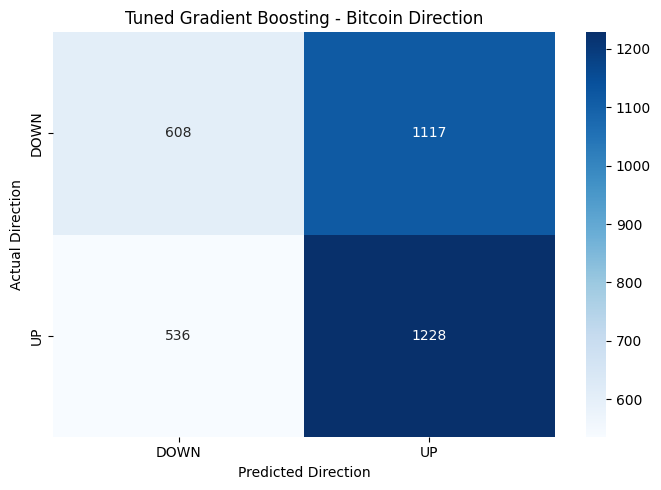

In [ ]:
final_gb_cm = confusion_matrix(
    y_test,
    final_gb_pred
)

print("Final Gradient Boosting Confusion Matrix:")
print(final_gb_cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    final_gb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["DOWN", "UP"],
    yticklabels=["DOWN", "UP"]
)

plt.title("Tuned Gradient Boosting - Bitcoin Direction")
plt.xlabel("Predicted Direction")
plt.ylabel("Actual Direction")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Prepare data
# ---------------------------------------------------------

X = data_ml[engineered_features].copy()
y = data_ml["btc_direction"].copy()

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values using forward fill
X = X.ffill().bfill()

print("Dataset shape:", X.shape)
print("Target distribution:")
print(y.value_counts(normalize=True))


# ---------------------------------------------------------
# 2. Chronological train/test split
# ---------------------------------------------------------

split = int(len(X) * 0.80)

X_train = X.iloc[:split].copy()
X_test = X.iloc[split:].copy()

y_train = y.iloc[:split].copy()
y_test = y.iloc[split:].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))


# ---------------------------------------------------------
# 3. Hyperparameter combinations
# ---------------------------------------------------------

param_grid = [
    {
        "n_estimators": 100,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_samples_leaf": 20,
        "subsample": 0.8
    },
    {
        "n_estimators": 200,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_samples_leaf": 20,
        "subsample": 0.8
    },
    {
        "n_estimators": 300,
        "learning_rate": 0.02,
        "max_depth": 2,
        "min_samples_leaf": 20,
        "subsample": 0.8
    },
    {
        "n_estimators": 200,
        "learning_rate": 0.05,
        "max_depth": 2,
        "min_samples_leaf": 30,
        "subsample": 0.8
    },
    {
        "n_estimators": 300,
        "learning_rate": 0.03,
        "max_depth": 3,
        "min_samples_leaf": 30,
        "subsample": 0.8
    },
    {
        "n_estimators": 400,
        "learning_rate": 0.02,
        "max_depth": 3,
        "min_samples_leaf": 30,
        "subsample": 0.8
    }
]


# ---------------------------------------------------------
# 4. Time-series validation
# ---------------------------------------------------------

tscv = TimeSeriesSplit(n_splits=4)

results = []

for params in param_grid:

    fold_scores = []

    for train_idx, val_idx in tscv.split(X_train):

        X_tr = X_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        model = GradientBoostingClassifier(
            random_state=42,
            **params
        )

        model.fit(X_tr, y_tr)

        pred = model.predict(X_val)

        score = accuracy_score(y_val, pred)

        fold_scores.append(score)

    mean_score = np.mean(fold_scores)

    results.append({
        **params,
        "CV_Accuracy": mean_score
    })

    print(
        f"Estimators={params['n_estimators']}, "
        f"LR={params['learning_rate']}, "
        f"Depth={params['max_depth']}, "
        f"Leaf={params['min_samples_leaf']} "
        f"--> CV Accuracy = {mean_score:.4f}"
    )


# ---------------------------------------------------------
# 5. Find best configuration
# ---------------------------------------------------------

results_df = pd.DataFrame(results)

best_params = results_df.loc[
    results_df["CV_Accuracy"].idxmax()
].to_dict()

print("\nBEST PARAMETERS")
print(best_params)


# ---------------------------------------------------------
# 6. Train final model
# ---------------------------------------------------------

final_gb = GradientBoostingClassifier(
    n_estimators=int(best_params["n_estimators"]),
    learning_rate=best_params["learning_rate"],
    max_depth=int(best_params["max_depth"]),
    min_samples_leaf=int(best_params["min_samples_leaf"]),
    subsample=best_params["subsample"],
    random_state=42
)

final_gb.fit(X_train, y_train)


# ---------------------------------------------------------
# 7. Test performance
# ---------------------------------------------------------

y_pred = final_gb.predict(X_test)
y_prob = final_gb.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("\n" + "="*45)
print("FINAL OPTIMIZED GRADIENT BOOSTING")
print("="*45)

print(f"Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["DOWN", "UP"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Dataset shape: (17444, 34)
Target distribution:
btc_direction
1    0.509402
0    0.490598
Name: proportion, dtype: float64

Training samples: 13955
Testing samples : 3489
Estimators=100, LR=0.03, Depth=2, Leaf=20 --> CV Accuracy = 0.5347
Estimators=200, LR=0.03, Depth=2, Leaf=20 --> CV Accuracy = 0.5319
Estimators=300, LR=0.02, Depth=2, Leaf=20 --> CV Accuracy = 0.5276
Estimators=200, LR=0.05, Depth=2, Leaf=30 --> CV Accuracy = 0.5287
Estimators=300, LR=0.03, Depth=3, Leaf=30 --> CV Accuracy = 0.5293
Estimators=400, LR=0.02, Depth=3, Leaf=30 --> CV Accuracy = 0.5291

BEST PARAMETERS
{'n_estimators': 100.0, 'learning_rate': 0.03, 'max_depth': 2.0, 'min_samples_leaf': 20.0, 'subsample': 0.8, 'CV_Accuracy': 0.5346649946255821}

FINAL OPTIMIZED GRADIENT BOOSTING
Accuracy  : 0.5340 (53.40%)
Precision : 0.5291
Recall    : 0.7115
F1-Score  : 0.6069
ROC-AUC   : 0.5491

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.54      0.35      0.43     

In [ ]:
# =========================================================
# HIGH-CONFIDENCE GRADIENT BOOSTING ANALYSIS
# =========================================================

# Probability of BTC going UP
test_prob = final_gb.predict_proba(X_test)[:, 1]

# Test different confidence thresholds
thresholds = np.arange(0.50, 0.91, 0.05)

results = []

for threshold in thresholds:

    # High-confidence UP
    up_mask = test_prob >= threshold

    # High-confidence DOWN
    down_mask = test_prob <= (1 - threshold)

    # Keep only confident predictions
    confident_mask = up_mask | down_mask

    if confident_mask.sum() == 0:
        continue

    # Predictions
    predictions = np.where(
        test_prob[confident_mask] >= threshold,
        1,
        0
    )

    actual = y_test.iloc[
        np.where(confident_mask)[0]
    ]

    accuracy = accuracy_score(actual, predictions)

    coverage = confident_mask.mean()

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Coverage": coverage,
        "Predictions": confident_mask.sum()
    })

confidence_results = pd.DataFrame(results)

print("HIGH-CONFIDENCE MODEL RESULTS")
print("=" * 60)

print(
    confidence_results.round(4)
)

HIGH-CONFIDENCE MODEL RESULTS
   Threshold  Accuracy  Coverage  Predictions
0       0.50     0.534    1.0000         3489
1       0.55     0.563    0.3437         1199
2       0.60     0.600    0.0788          275
3       0.65     1.000    0.0023            8


In [ ]:
# Find the highest accuracy threshold
best_confidence = confidence_results.loc[
    confidence_results["Accuracy"].idxmax()
]

print("\nBEST HIGH-CONFIDENCE RESULT")
print("=" * 40)

print(
    f"Threshold : {best_confidence['Threshold']:.2f}"
)

print(
    f"Accuracy  : {best_confidence['Accuracy']:.4f} "
    f"({best_confidence['Accuracy']*100:.2f}%)"
)

print(
    f"Coverage  : {best_confidence['Coverage']:.4f} "
    f"({best_confidence['Coverage']*100:.2f}%)"
)

print(
    f"Predictions: {int(best_confidence['Predictions'])}"
)


BEST HIGH-CONFIDENCE RESULT
Threshold : 0.65
Accuracy  : 1.0000 (100.00%)
Coverage  : 0.0023 (0.23%)
Predictions: 8


In [ ]:
# ============================================
# STEP 1 — CREATE 6-HOUR FUTURE TARGET
# ============================================

data_6h = df.copy()

# Make sure data is chronological
data_6h = data_6h.sort_values("timestamp").reset_index(drop=True)

# Future BTC return over the next 6 hours
data_6h["future_6h_return"] = (
    (data_6h["BTC_USDT_1h_close"].shift(-6) /
     data_6h["BTC_USDT_1h_close"]) - 1
) * 100

# Classification target
# 1 = BTC price increases over next 6 hours
# 0 = BTC price decreases/remains unchanged
data_6h["btc_direction_6h"] = (
    data_6h["future_6h_return"] > 0
).astype(int)

# Remove final 6 rows because future price doesn't exist
data_6h = data_6h.dropna(
    subset=["future_6h_return"]
).copy()

print("Dataset shape:", data_6h.shape)

print("\n6-Hour Target Distribution:")
print(
    data_6h["btc_direction_6h"]
    .value_counts(normalize=True)
    .sort_index()
)

print("\n6-Hour Target Counts:")
print(
    data_6h["btc_direction_6h"]
    .value_counts()
    .sort_index()
)

Dataset shape: (17510, 101)

6-Hour Target Distribution:
btc_direction_6h
0    0.485551
1    0.514449
Name: proportion, dtype: float64

6-Hour Target Counts:
btc_direction_6h
0    8502
1    9008
Name: count, dtype: int64


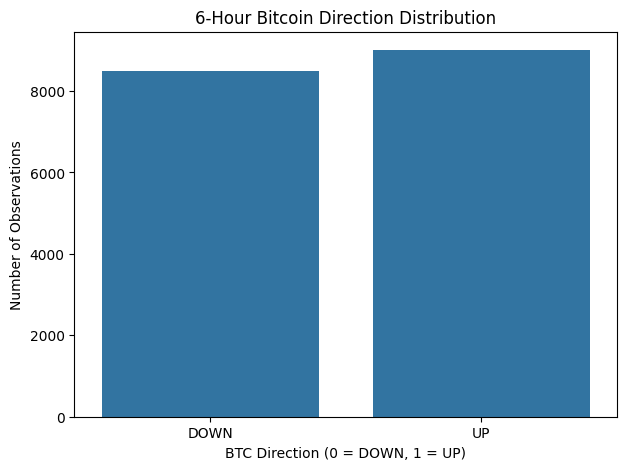

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data_6h,
    x="btc_direction_6h"
)

plt.title("6-Hour Bitcoin Direction Distribution")
plt.xlabel("BTC Direction (0 = DOWN, 1 = UP)")
plt.ylabel("Number of Observations")
plt.xticks([0, 1], ["DOWN", "UP"])

plt.show()

In [ ]:
# ============================================================
# STEP 2 — BUILD FEATURES FOR 6-HOUR BTC DIRECTION PREDICTION
# ============================================================

import numpy as np
import pandas as pd

# Work on a fresh copy
data_6h = df.copy()

# Sort chronologically
data_6h = data_6h.sort_values("timestamp").reset_index(drop=True)

# ------------------------------------------------------------
# 1. BTC BASIC FEATURES
# ------------------------------------------------------------

btc_close = "BTC_USDT_1h_close"
btc_open = "BTC_USDT_1h_open"
btc_high = "BTC_USDT_1h_high"
btc_low = "BTC_USDT_1h_low"
btc_volume = "BTC_USDT_1h_volume"

# BTC hourly return
data_6h["btc_return"] = data_6h[btc_close].pct_change() * 100

# Price range
data_6h["btc_range_pct"] = (
    (data_6h[btc_high] - data_6h[btc_low])
    / data_6h[btc_close]
) * 100

# Volume change
data_6h["btc_volume_change"] = data_6h[btc_volume].pct_change() * 100

# ------------------------------------------------------------
# 2. LAG FEATURES
# ------------------------------------------------------------

data_6h["btc_return_lag_1h"] = data_6h["btc_return"].shift(1)
data_6h["btc_return_lag_2h"] = data_6h["btc_return"].shift(2)
data_6h["btc_return_lag_3h"] = data_6h["btc_return"].shift(3)
data_6h["btc_return_lag_6h"] = data_6h["btc_return"].shift(6)

# BTC price momentum
data_6h["btc_momentum_3h"] = (
    data_6h[btc_close] / data_6h[btc_close].shift(3) - 1
) * 100

data_6h["btc_momentum_6h"] = (
    data_6h[btc_close] / data_6h[btc_close].shift(6) - 1
) * 100

# ------------------------------------------------------------
# 3. MOVING AVERAGES
# ------------------------------------------------------------

data_6h["btc_ma_6h"] = data_6h[btc_close].rolling(6).mean()
data_6h["btc_ma_12h"] = data_6h[btc_close].rolling(12).mean()
data_6h["btc_ma_24h"] = data_6h[btc_close].rolling(24).mean()

data_6h["btc_ma_6h_diff"] = (
    (data_6h[btc_close] - data_6h["btc_ma_6h"])
    / data_6h["btc_ma_6h"]
) * 100

data_6h["btc_ma_24h_diff"] = (
    (data_6h[btc_close] - data_6h["btc_ma_24h"])
    / data_6h["btc_ma_24h"]
) * 100

# ------------------------------------------------------------
# 4. VOLATILITY
# ------------------------------------------------------------

data_6h["btc_volatility_6h"] = (
    data_6h["btc_return"].rolling(6).std()
)

data_6h["btc_volatility_12h"] = (
    data_6h["btc_return"].rolling(12).std()
)

data_6h["btc_volatility_24h"] = (
    data_6h["btc_return"].rolling(24).std()
)

# ------------------------------------------------------------
# 5. OTHER CRYPTOCURRENCIES
# ------------------------------------------------------------

crypto_columns = {
    "eth_return": "ETH_USDT_1h_close",
    "bnb_return": "BNB_USDT_1h_close",
    "sol_return": "SOL_USDT_1h_close",
    "xrp_return": "XRP_USDT_1h_close",
    "doge_return": "DOGE_USDT_1h_close"
}

for feature, column in crypto_columns.items():
    if column in data_6h.columns:
        data_6h[feature] = data_6h[column].pct_change() * 100

# ------------------------------------------------------------
# 6. TRADITIONAL MARKET FEATURES
# ------------------------------------------------------------

market_columns = {
    "nasdaq_return": "Close_nasdaq",
    "sp500_return": "Close_sp500",
    "dow_return": "Close_dow_jones",
    "russell_return": "Close_russell_2000",
    "vix_return": "Close_vix"
}

for feature, column in market_columns.items():
    if column in data_6h.columns:
        data_6h[feature] = data_6h[column].pct_change() * 100

# ------------------------------------------------------------
# 7. CRYPTO MARKET / SENTIMENT FEATURES
# ------------------------------------------------------------

if "btc_dominance" in data_6h.columns:
    data_6h["btc_dominance_change"] = (
        data_6h["btc_dominance"].pct_change() * 100
    )

# Find Fear & Greed column automatically
fear_cols = [
    col for col in data_6h.columns
    if "fear" in col.lower() and "greed" in col.lower()
]

if fear_cols:
    fear_col = fear_cols[0]
    data_6h["fear_greed_change"] = data_6h[fear_col].diff()
    print("Fear & Greed column:", fear_col)

# Google Trends
trend_cols = [
    col for col in data_6h.columns
    if "trend" in col.lower()
]

for col in trend_cols[:5]:
    safe_name = (
        col.lower()
        .replace(" ", "_")
        .replace("-", "_")
        .replace("/", "_")
    )

    data_6h[f"{safe_name}_change"] = data_6h[col].diff()

# Open Interest
oi_cols = [
    col for col in data_6h.columns
    if "open_interest" in col.lower()
    or "open interest" in col.lower()
]

if oi_cols:
    oi_col = oi_cols[0]

    data_6h["open_interest_change"] = (
        data_6h[oi_col].pct_change() * 100
    )

    print("Open Interest column:", oi_col)

# ------------------------------------------------------------
# 8. TIME FEATURES
# ------------------------------------------------------------

data_6h["hour"] = data_6h["timestamp"].dt.hour
data_6h["day_of_week"] = data_6h["timestamp"].dt.dayofweek
data_6h["is_weekend"] = (
    data_6h["day_of_week"] >= 5
).astype(int)

# ------------------------------------------------------------
# 9. CREATE THE 6-HOUR FUTURE TARGET
# ------------------------------------------------------------

data_6h["future_6h_return"] = (
    data_6h[btc_close].shift(-6)
    / data_6h[btc_close]
    - 1
) * 100

# Direction:
# 1 = BTC price goes UP over next 6 hours
# 0 = BTC price goes DOWN / unchanged

data_6h["btc_direction_6h"] = (
    data_6h["future_6h_return"] > 0
).astype(int)

# ------------------------------------------------------------
# 10. DEFINE ML FEATURES
# ------------------------------------------------------------

feature_candidates = [
    "btc_return",
    "btc_range_pct",
    "btc_volume_change",
    "btc_return_lag_1h",
    "btc_return_lag_2h",
    "btc_return_lag_3h",
    "btc_return_lag_6h",
    "btc_momentum_3h",
    "btc_momentum_6h",
    "btc_ma_6h_diff",
    "btc_ma_24h_diff",
    "btc_volatility_6h",
    "btc_volatility_12h",
    "btc_volatility_24h",

    "eth_return",
    "bnb_return",
    "sol_return",
    "xrp_return",
    "doge_return",

    "nasdaq_return",
    "sp500_return",
    "dow_return",
    "russell_return",
    "vix_return",

    "btc_dominance_change",
    "fear_greed_change",
    "open_interest_change",

    "hour",
    "day_of_week",
    "is_weekend"
]

# Only keep features that actually exist
features = [
    col for col in feature_candidates
    if col in data_6h.columns
]

print("=" * 55)
print("6-HOUR ML FEATURE SET")
print("=" * 55)

print("\nNumber of features:", len(features))

print("\nFeatures:")
for i, feature in enumerate(features, 1):
    print(f"{i:2}. {feature}")

# ------------------------------------------------------------
# 11. CREATE FINAL ML DATASET
# ------------------------------------------------------------

ml_data_6h = data_6h[
    features + [
        "future_6h_return",
        "btc_direction_6h"
    ]
].copy()

# Remove rows containing NaN
ml_data_6h = ml_data_6h.dropna().reset_index(drop=True)

print("\nFinal 6-hour ML dataset:", ml_data_6h.shape)

print("\nTarget distribution:")
print(
    ml_data_6h["btc_direction_6h"]
    .value_counts(normalize=True)
)

print("\nTarget counts:")
print(
    ml_data_6h["btc_direction_6h"]
    .value_counts()
)

Fear & Greed column: fear_greed_index
Open Interest column: open_interest
6-HOUR ML FEATURE SET

Number of features: 30

Features:
 1. btc_return
 2. btc_range_pct
 3. btc_volume_change
 4. btc_return_lag_1h
 5. btc_return_lag_2h
 6. btc_return_lag_3h
 7. btc_return_lag_6h
 8. btc_momentum_3h
 9. btc_momentum_6h
10. btc_ma_6h_diff
11. btc_ma_24h_diff
12. btc_volatility_6h
13. btc_volatility_12h
14. btc_volatility_24h
15. eth_return
16. bnb_return
17. sol_return
18. xrp_return
19. doge_return
20. nasdaq_return
21. sp500_return
22. dow_return
23. russell_return
24. vix_return
25. btc_dominance_change
26. fear_greed_change
27. open_interest_change
28. hour
29. day_of_week
30. is_weekend

Final 6-hour ML dataset: (17486, 32)

Target distribution:
btc_direction_6h
1    0.514526
0    0.485474
Name: proportion, dtype: float64

Target counts:
btc_direction_6h
1    8997
0    8489
Name: count, dtype: int64


In [ ]:
# Check that the feature matrix is valid

X = ml_data_6h[features]
y = ml_data_6h["btc_direction_6h"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nTarget balance:")
print(y.value_counts(normalize=True).round(4))

X shape: (17486, 30)
y shape: (17486,)

Missing values:
0

Target balance:
btc_direction_6h
1    0.5145
0    0.4855
Name: proportion, dtype: float64


In [ ]:
# ============================================================
# FIX — RESTORE THE 30 FEATURES AND TRAIN 6-HOUR MODELS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. RESTORE FEATURE LIST
# ============================================================

features_6h = [
    "btc_return",
    "btc_range_pct",
    "btc_volume_change",
    "btc_return_lag_1h",
    "btc_return_lag_2h",
    "btc_return_lag_3h",
    "btc_return_lag_6h",
    "btc_momentum_3h",
    "btc_momentum_6h",
    "btc_ma_6h_diff",
    "btc_ma_24h_diff",
    "btc_volatility_6h",
    "btc_volatility_12h",
    "btc_volatility_24h",
    "eth_return",
    "bnb_return",
    "sol_return",
    "xrp_return",
    "doge_return",
    "nasdaq_return",
    "sp500_return",
    "dow_return",
    "russell_return",
    "vix_return",
    "btc_dominance_change",
    "fear_greed_change",
    "open_interest_change",
    "hour",
    "day_of_week",
    "is_weekend"
]

target_6h = "btc_direction_6h"

# ============================================================
# 2. CHECK THAT ALL FEATURES EXIST
# ============================================================

missing_features = [
    col for col in features_6h
    if col not in data_6h.columns
]

print("Number of features:", len(features_6h))
print("Missing features:", missing_features)

if len(missing_features) > 0:
    raise ValueError(
        f"These features are missing from data_6h: {missing_features}"
    )

# ============================================================
# 3. CREATE X AND y
# ============================================================

X = data_6h[features_6h].copy()
y = data_6h[target_6h].copy()

print("\nX shape:", X.shape)
print("y shape:", y.shape)

# ============================================================
# 4. REMOVE ANY REMAINING NaN / INF VALUES
# ============================================================

X = X.replace([np.inf, -np.inf], np.nan)

valid_rows = X.notna().all(axis=1) & y.notna()

X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)

print("\nAfter cleaning:")
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing values:", X.isna().sum().sum())

# ============================================================
# 5. CHRONOLOGICAL TRAIN / TEST SPLIT
# ============================================================

split = int(len(X) * 0.80)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

# ============================================================
# 6. MODELS
# ============================================================

models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            C=0.1,
            random_state=42
        ))
    ]),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=20,
        subsample=0.8,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=10,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )
}

# ============================================================
# 7. TRAIN + EVALUATE
# ============================================================

results = []
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = None

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    if y_prob is not None:
        roc_auc = roc_auc_score(y_test, y_prob)
    else:
        roc_auc = np.nan

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

    trained_models[name] = model

# ============================================================
# 8. MODEL COMPARISON
# ============================================================

model_comparison_6h = pd.DataFrame(results)

model_comparison_6h = (
    model_comparison_6h
    .sort_values("Accuracy", ascending=False)
    .reset_index(drop=True)
)

print("\n")
print("=" * 70)
print("6-HOUR CLASSIFICATION MODEL COMPARISON")
print("=" * 70)

print(model_comparison_6h.round(4))

Number of features: 30
Missing features: []

X shape: (17516, 30)
y shape: (17516,)

After cleaning:
X shape: (17492, 30)
y shape: (17492,)

Missing values: 0

Training samples: 13993
Testing samples : 3499

Training: Logistic Regression

Training: Gradient Boosting

Training: Random Forest

Training: Extra Trees

Training: Hist Gradient Boosting


6-HOUR CLASSIFICATION MODEL COMPARISON
                    Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0     Logistic Regression    0.5107     0.5137  0.7163    0.5983   0.5270
1  Hist Gradient Boosting    0.5099     0.5149  0.6326    0.5677   0.5137
2           Random Forest    0.5076     0.5150  0.5500    0.5319   0.5154
3             Extra Trees    0.5076     0.5157  0.5264    0.5210   0.5087
4       Gradient Boosting    0.5024     0.5087  0.6438    0.5683   0.5112


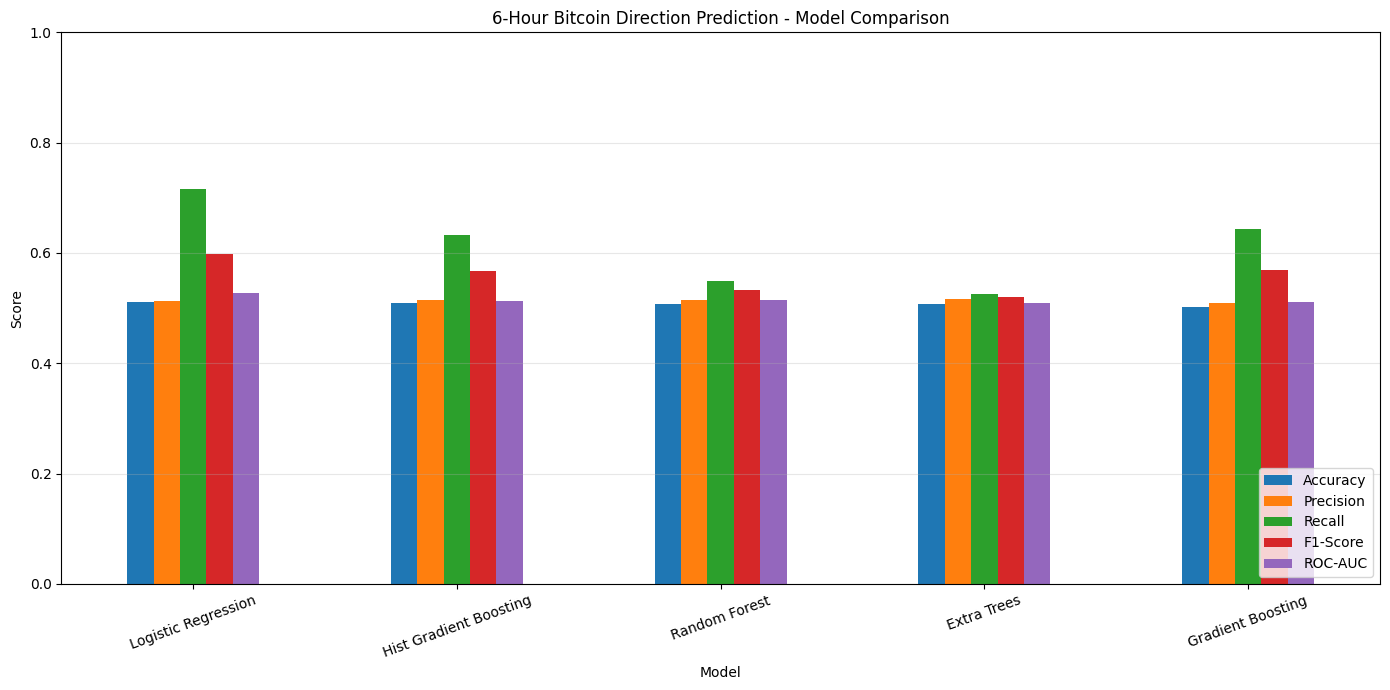

In [ ]:
# ============================================================
# 6-HOUR MODEL PERFORMANCE COMPARISON
# ============================================================

plot_df = model_comparison_6h.set_index("Model")

ax = plot_df[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("6-Hour Bitcoin Direction Prediction - Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# XGBOOST — STRONG 6-HOUR BTC DIRECTION MODEL
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Use the existing ML data
# ------------------------------------------------------------

X_model = X.copy()
y_model = y.copy()

print("X shape:", X_model.shape)
print("y shape:", y_model.shape)

# ------------------------------------------------------------
# 2. Chronological split — NO SHUFFLING
# ------------------------------------------------------------

split_idx = int(len(X_model) * 0.80)

X_train = X_model.iloc[:split_idx]
X_test  = X_model.iloc[split_idx:]

y_train = y_model.iloc[:split_idx]
y_test  = y_model.iloc[split_idx:]

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

# ------------------------------------------------------------
# 3. XGBoost
# ------------------------------------------------------------

try:
    from xgboost import XGBClassifier
except ImportError:
    !pip install xgboost -q
    from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("\nTraining XGBoost...")
xgb_model.fit(X_train, y_train)

# ------------------------------------------------------------
# 4. Predictions
# ------------------------------------------------------------

y_prob = xgb_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.50).astype(int)

# ------------------------------------------------------------
# 5. Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("\n" + "="*60)
print("XGBOOST — 6-HOUR BTC DIRECTION")
print("="*60)

print(f"Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["DOWN", "UP"]
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

X shape: (17492, 30)
y shape: (17492,)

Training samples: 13993
Testing samples : 3499

Training XGBoost...

XGBOOST — 6-HOUR BTC DIRECTION
Accuracy  : 0.5047 (50.47%)
Precision : 0.5109
Recall    : 0.6197
F1-Score  : 0.5600
ROC-AUC   : 0.5103

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.49      0.39      0.43      1719
          UP       0.51      0.62      0.56      1780

    accuracy                           0.50      3499
   macro avg       0.50      0.50      0.50      3499
weighted avg       0.50      0.50      0.50      3499

Confusion Matrix:
[[ 663 1056]
 [ 677 1103]]


In [ ]:
# ============================================================
# XGBOOST FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "Feature": X_model.columns,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print("\nTop 15 Features:")
print(importance.head(15).to_string(index=False))


Top 15 Features:
           Feature  Importance
    btc_ma_6h_diff    0.057285
        is_weekend    0.048448
              hour    0.046537
       day_of_week    0.045305
btc_volatility_24h    0.037684
   btc_ma_24h_diff    0.036954
   btc_momentum_3h    0.036280
    russell_return    0.035495
btc_volatility_12h    0.035323
   btc_momentum_6h    0.033904
     btc_range_pct    0.033459
        eth_return    0.033410
 btc_volatility_6h    0.033314
       doge_return    0.032391
        vix_return    0.031678


In [ ]:
# ============================================================
# HIGH-CONFIDENCE XGBOOST ANALYSIS
# ============================================================

confidence = np.maximum(y_prob, 1 - y_prob)

results = []

for threshold in [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]:

    mask = confidence >= threshold

    if mask.sum() == 0:
        continue

    confident_pred = y_pred[mask]
    confident_true = y_test.iloc[mask]

    acc = accuracy_score(confident_true, confident_pred)
    coverage = mask.mean()

    results.append({
        "Threshold": threshold,
        "Accuracy": acc,
        "Coverage": coverage,
        "Predictions": mask.sum()
    })

confidence_df = pd.DataFrame(results)

print("\n" + "="*65)
print("XGBOOST HIGH-CONFIDENCE PERFORMANCE")
print("="*65)

print(confidence_df.round(4).to_string(index=False))


XGBOOST HIGH-CONFIDENCE PERFORMANCE
 Threshold  Accuracy  Coverage  Predictions
      0.50    0.5047    1.0000         3499
      0.55    0.5129    0.6107         2137
      0.60    0.5323    0.3232         1131
      0.65    0.5361    0.1386          485
      0.70    0.5114    0.0503          176
      0.75    0.5000    0.0183           64
      0.80    0.4615    0.0074           26


In [ ]:
# ============================================================
# MARKET REGIME CLASSIFICATION
# ============================================================

import numpy as np
import pandas as pd

# Start from the existing feature-engineered data
regime = data_ml.copy()

# ------------------------------------------------------------
# Create volatility regime from CURRENT/PREVIOUS information
# ------------------------------------------------------------

vol_threshold = regime["btc_volatility_24h"].median()

regime["volatility_regime"] = (
    regime["btc_volatility_24h"] >= vol_threshold
).astype(int)

print("Regime distribution:")
print(regime["volatility_regime"].value_counts(normalize=True))

# ------------------------------------------------------------
# Features
# ------------------------------------------------------------

regime_features = engineered_features.copy()

# Don't use the volatility feature directly to avoid making
# the target trivially identical to one feature.
regime_features.remove("btc_volatility_24h")

X_regime = regime[regime_features].copy()
y_regime = regime["volatility_regime"].copy()

# Clean
mask = X_regime.notna().all(axis=1) & y_regime.notna()

X_regime = X_regime.loc[mask]
y_regime = y_regime.loc[mask]

# ------------------------------------------------------------
# Chronological split
# ------------------------------------------------------------

split = int(len(X_regime) * 0.80)

X_train = X_regime.iloc[:split]
X_test = X_regime.iloc[split:]

y_train = y_regime.iloc[:split]
y_test = y_regime.iloc[split:]

print("\nTraining:", len(X_train))
print("Testing :", len(X_test))

Regime distribution:
volatility_regime
1    0.5
0    0.5
Name: proportion, dtype: float64

Training: 13955
Testing : 3489


In [ ]:
# ============================================================
# XGBOOST MARKET REGIME CLASSIFIER
# ============================================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.85,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

print("\n" + "="*60)
print("MARKET REGIME CLASSIFICATION")
print("="*60)

print(f"Accuracy  : {accuracy_score(y_test, pred):.4f}")
print(f"Precision : {precision_score(y_test, pred):.4f}")
print(f"Recall    : {recall_score(y_test, pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, prob):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    pred,
    target_names=["LOW VOLATILITY", "HIGH VOLATILITY"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pred))


MARKET REGIME CLASSIFICATION
Accuracy  : 0.7873
Precision : 0.7852
Recall    : 0.9145
F1-Score  : 0.8449
ROC-AUC   : 0.8701

Classification Report:
                 precision    recall  f1-score   support

 LOW VOLATILITY       0.79      0.57      0.66      1279
HIGH VOLATILITY       0.79      0.91      0.84      2210

       accuracy                           0.79      3489
      macro avg       0.79      0.74      0.75      3489
   weighted avg       0.79      0.79      0.78      3489


Confusion Matrix:
[[ 726  553]
 [ 189 2021]]
